# Pipeline de análise — as letras de diferentes países estão ficando parecidas?

Entrada: `finalData.csv` (top 40 anual por país, com letra original, idioma e tradução `letra_en`). Se ele não existir, usa `completoComLetras.csv` + `letras_en.jsonl`.

**Versão principal: letras traduzidas para o inglês.** Com a letra original, os clusters separam sobretudo o
*idioma* (NMI ≈ 0,5 entre cluster e idioma): parte da "diferença entre países" seria só diferença de língua.
Com a tradução, o que sobra é conteúdo. A versão original continua sendo calculada na seção 10, como comparação.
Para trocar: `VERSAO=original`.

Etapas (seguem a seção *Metodologia* da proposta):

1. Limpeza das letras, deduplicação dentro da célula e detecção de idioma
2. Embeddings multilíngues (LaBSE por padrão), com letras longas divididas em trechos e média dos vetores — **com cache em `dados/embeddings/`**
3. UMAP + K-Means (k por silhueta) e HDBSCAN para comparação
4. Interpretação dos clusters (c-TF-IDF, a mesma ideia do BERTopic) e diagnóstico de viés de idioma
5. Similaridade entre países: **1 − JS** (base 2) das distribuições sobre clusters e **cosseno entre centroides**; série $S_t$
6. Tendência: inclinação (regressão linear) + Spearman, IC 95% por **bootstrap** de músicas dentro das células; **teste de permutação** dos rótulos de país
7. Hipóteses H1 (EUA, BR, MX, ES convergem) e H2 (Japão se mantém distante)
8. Grafo de países + Louvain, com a **modularidade comparada a um modelo nulo** (rótulos de país embaralhados)
9. Controles: músicas compartilhadas × exclusivas
10. Comparação original × traduzida: repete S_t, H1/H2 e o controle de exclusivas nas duas versões
11. **Robustez do H1**: sementes e valores de k, composição de idiomas fixa, só músicas no idioma local, e as duas métricas lado a lado para o inglês

Saídas em `resultados/` (CSVs e figuras). **Nenhuma letra é gravada nas saídas**, só vetores, rótulos e métricas.

Funções comuns a todos os notebooks (limpeza, chave da música, estilo) estão em `comum.py`.
Notebooks complementares: `pipelineRedes.ipynb` (redes de 37 países e de colaborações), `pipelineToxicidade.ipynb` (conteúdo explícito/tóxico) e `pipelineDifusao.ipynb` (difusão entre países).

Dependências: `pip install -r requirements.txt`

In [1]:
import os, re, hashlib, itertools, unicodedata, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import spearmanr, linregress
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
import networkx as nx
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="umap")

# ---------- entradas / saídas ----------
ARQ_DADOS = Path("./finalData.csv") if Path("./finalData.csv").exists() else Path("./completoComLetras.csv")
ARQ_TRAD  = Path("./letras_en.jsonl")   # só usado se ARQ_DADOS não tiver a coluna letra_en
PASTA_EMB = Path("./dados/embeddings")   # só vetores (podem ser divulgados)
PASTA_RES = Path("./resultados")
PASTA_EMB.mkdir(parents=True, exist_ok=True)
PASTA_RES.mkdir(parents=True, exist_ok=True)

# ---------- parâmetros ----------
MODELO     = os.environ.get("MODELO_EMB", "sentence-transformers/LaBSE")  # alternativa: "intfloat/multilingual-e5-base"
VERSAO     = os.environ.get("VERSAO", "traduzida")   # versão principal das letras: "traduzida" (padrão) ou "original"
BATCH      = 32
EXCLUIR    = []          # células (país, ano) a remover, ex.: [("jp", 2017)]
K_MIN, K_MAX = 5, 25     # faixa de k testada no K-Means
UMAP_DIM   = 10          # dimensões do UMAP usado para clusterizar
MIN_CELULA = 10          # mínimo de músicas para uma célula entrar nos controles
N_BOOT     = int(os.environ.get("N_BOOT", 1000))
N_PERM     = int(os.environ.get("N_PERM", 1000))
N_PERM_Q   = int(os.environ.get("N_PERM_Q", 500))   # permutações do nulo da modularidade (seção 7)
SEED       = 42

PAISES   = ["us", "br", "mx", "es", "au", "jp"]
NOMES    = {"us": "EUA", "br": "Brasil", "mx": "México", "es": "Espanha", "au": "Austrália", "jp": "Japão"}
GRUPO_H1 = ["us", "br", "mx", "es"]   # H1: convergência entre países ligados à indústria global
GRUPO_H2 = ["jp"]                     # H2: distância mantida

# ---------- estilo dos gráficos ----------
COR = {"s1": "#2a78d6", "s2": "#eb6834", "s3": "#1baf7a", "neutro": "#b9b8b3",
       "texto": "#0b0b0b", "texto2": "#52514e", "grade": "#e6e5e1", "fundo": "#fcfcfb"}
SEQ = LinearSegmentedColormap.from_list("seq_azul", ["#cde2fb", "#86b6ef", "#2a78d6", "#1c5cab", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div", ["#e34948", "#f0efec", "#2a78d6"])  # vermelho = afastando · azul = aproximando
plt.rcParams.update({
    "figure.facecolor": COR["fundo"], "axes.facecolor": COR["fundo"], "savefig.facecolor": COR["fundo"],
    "axes.edgecolor": COR["grade"], "axes.labelcolor": COR["texto2"], "text.color": COR["texto"],
    "xtick.color": COR["texto2"], "ytick.color": COR["texto2"],
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": COR["grade"], "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2, "lines.markersize": 6, "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "legend.frameon": False,
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
})

## 1. Dados, limpeza e idioma

In [2]:
# limpa_letra (remove LRC e rótulos como "[Refrão]") e chave_musica (mesma música com track_ids diferentes)
# ficam em comum.py, para que todos os notebooks usem exatamente a mesma definição
from comum import limpa_letra, chave_musica, _LRC

dados = pd.read_csv(ARQ_DADOS)
dados = dados[dados["cc"].isin(PAISES)].copy()
for cc, ano in EXCLUIR:
    dados = dados[~((dados["cc"] == cc) & (dados["year"] == ano))]

n_lrc = dados["letra"].fillna("").str.contains(_LRC).sum()
dados["letra_limpa"] = dados["letra"].map(limpa_letra)
dados["chave"] = [chave_musica(t, a) for t, a in zip(dados["title"], dados["artists"])]

antes = len(dados)
dados = (dados.sort_values("pontos", ascending=False)
              .drop_duplicates(["cc", "year", "chave"])            # mesma música 2x na mesma célula
              .sort_values(["cc", "year", "pontos"], ascending=[True, True, False]))
dup = antes - len(dados)
dados = dados[dados["letra_limpa"].str.len() >= 30]               # sem letra útil

print(f"linhas com resíduo de LRC limpas: {n_lrc} | duplicatas removidas dentro das células: {dup}")
print(f"{len(dados)} linhas (país × ano × música) | {dados['track_id'].nunique()} faixas únicas")
display(dados.groupby(["cc", "year"]).size().unstack())

linhas com resíduo de LRC limpas: 16 | duplicatas removidas dentro das células: 3
2156 linhas (país × ano × música) | 1444 faixas únicas


year,2017,2018,2019,2020,2021,2022,2023,2024,2025
cc,,,,,,,,,
au,40,40,40,40,40,40,40,40,40
br,39,39,40,40,40,40,40,40,40
es,40,40,40,40,40,40,40,40,40
jp,39,40,40,40,40,40,40,40,40
mx,40,40,40,40,40,40,40,40,40
us,40,40,40,40,39,40,40,40,40


In [3]:
_limpa_en = lambda t: limpa_letra(t) if isinstance(t, str) and t.strip() else np.nan
faixas = dados.drop_duplicates("track_id").set_index("track_id")
faixas = faixas[["title", "artists", "chave", "letra_limpa"] + [c for c in ["letra_en", "idioma"] if c in faixas.columns]].copy()
faixas = faixas.rename(columns={"idioma": "idioma_trad"})
dados = dados.drop(columns=[c for c in ["idioma", "letra_en"] if c in dados.columns])

# traduções (robustez): coluna letra_en do CSV; senão, letras_en.jsonl
if "letra_en" in faixas.columns:
    faixas["letra_en"] = faixas["letra_en"].map(_limpa_en)
    print(f"traduções lidas de {ARQ_DADOS}")
elif ARQ_TRAD.exists():
    tr = pd.read_json(ARQ_TRAD, lines=True).drop_duplicates("track_id").set_index("track_id")
    faixas["letra_en"] = tr["letra_en"].reindex(faixas.index).map(_limpa_en)
    faixas["idioma_trad"] = tr["idioma"].reindex(faixas.index)
else:
    faixas["letra_en"] = np.nan
if "idioma_trad" not in faixas.columns:
    faixas["idioma_trad"] = np.nan

# idioma
try:
    from langdetect import detect, DetectorFactory
    DetectorFactory.seed = 0
    def _detecta(t):
        try:
            return detect(t[:2000])
        except Exception:
            return None
    faixas["idioma"] = faixas["letra_limpa"].map(_detecta)
except ImportError:
    print("langdetect não instalado: usando o idioma que veio nos dados de tradução")
    faixas["idioma"] = faixas["idioma_trad"]
faixas["idioma"] = faixas["idioma"].where(faixas["idioma"].isin(["en", "es", "pt", "ja", "ko"]), "outro")

dados = dados.merge(faixas[["idioma"]], left_on="track_id", right_index=True, how="left")
print("idioma das faixas únicas:", faixas["idioma"].value_counts().to_dict())
print(f"faixas com tradução para o inglês: {faixas['letra_en'].notna().sum()} de {len(faixas)}")
print("\n% de músicas por idioma em cada país (todas as células somadas):")
display((pd.crosstab(dados["cc"], dados["idioma"], normalize="index") * 100).round(0))

traduções lidas de finalData.csv


idioma das faixas únicas: {'es': 494, 'en': 447, 'pt': 319, 'ja': 177, 'outro': 4, 'ko': 3}
faixas com tradução para o inglês: 1444 de 1444

% de músicas por idioma em cada país (todas as células somadas):


idioma,en,es,ja,ko,outro,pt
cc,,,,,,
au,100.0,0.0,0.0,0.0,0.0,0.0
br,6.0,1.0,0.0,0.0,0.0,92.0
es,7.0,92.0,0.0,0.0,0.0,0.0
jp,18.0,0.0,81.0,1.0,1.0,0.0
mx,8.0,92.0,0.0,0.0,0.0,0.0
us,97.0,3.0,0.0,0.0,0.0,0.0


## 2. Embeddings (letra original e traduzida)

Cada letra é dividida em trechos que cabem no limite de tokens do modelo (respeitando quebras de linha); os vetores dos trechos são normalizados, promediados e renormalizados.
O cache é indexado por `track_id` + hash do texto: se a letra mudar, só ela é recalculada. Em CPU, o LaBSE leva alguns minutos para as ~1.450 letras; em GPU, segundos.

In [4]:
_modelo = {}

def carrega_modelo():
    if "m" not in _modelo:
        import torch
        from sentence_transformers import SentenceTransformer
        from transformers.utils import logging as hf_logging
        hf_logging.set_verbosity_error()   # aviso de "sequence length" na contagem de tokens é inofensivo
        dev = "cuda" if torch.cuda.is_available() else "cpu"
        _modelo["m"] = SentenceTransformer(MODELO, device=dev)
        print(f"modelo {MODELO} em {dev} | max_seq_length = {_modelo['m'].max_seq_length}")
    return _modelo["m"]

def divide_trechos(texto, tok, max_tok):
    linhas = [l for l in texto.split("\n") if l.strip()]
    trechos, atual, n = [], [], 0
    for l in linhas:
        k = len(tok.tokenize(l)) + 1
        if atual and n + k > max_tok:
            trechos.append("\n".join(atual))
            atual, n = [], 0
        atual.append(l)
        n += k
    if atual:
        trechos.append("\n".join(atual))
    return trechos or [texto]

def _slug(s):
    return re.sub(r"[^\w]+", "_", s).strip("_")

def gera_embeddings(textos: pd.Series, nome: str) -> np.ndarray:
    # textos: Series indexada por track_id. Retorna matriz (n, d) na mesma ordem, linhas com norma 1.
    arq = PASTA_EMB / f"{_slug(MODELO)}__{nome}.npz"
    chaves = [f"{tid}:{hashlib.md5(t.encode('utf-8')).hexdigest()[:10]}" for tid, t in textos.items()]
    cache = {}
    if arq.exists():
        z = np.load(arq)
        cache = dict(zip(z["chaves"].tolist(), z["emb"]))
    falta = [(c, t) for c, t in zip(chaves, textos.values) if c not in cache]
    if falta:
        m = carrega_modelo()
        max_tok = m.max_seq_length - 8
        pref = "passage: " if "e5" in MODELO.lower() else ""
        pedacos, dono = [], []
        for c, t in falta:
            for b in divide_trechos(t, m.tokenizer, max_tok):
                pedacos.append(pref + b)
                dono.append(c)
        print(f"[{nome}] codificando {len(falta)} letras em {len(pedacos)} trechos...")
        V = m.encode(pedacos, batch_size=BATCH, normalize_embeddings=True, show_progress_bar=True, convert_to_numpy=True)
        dono = np.array(dono)
        for c, _ in falta:
            v = V[dono == c].mean(axis=0)
            cache[c] = v / np.linalg.norm(v)
        ks = list(cache)
        np.savez_compressed(arq, chaves=np.array(ks), emb=np.stack([cache[k] for k in ks]).astype(np.float32))
    else:
        print(f"[{nome}] {len(chaves)} embeddings lidos do cache {arq}")
    return np.stack([cache[c] for c in chaves]).astype(np.float32)

E_orig = gera_embeddings(faixas["letra_limpa"], "original")
POS = {t: i for i, t in enumerate(faixas.index)}   # track_id -> linha da matriz
if VERSAO == "traduzida" and faixas["letra_en"].notna().all():
    E_p = gera_embeddings(faixas["letra_en"], "traducao_en")
else:
    if VERSAO == "traduzida":
        print(f"ATENÇÃO: {faixas['letra_en'].isna().sum()} faixas sem tradução -> usando a letra original como versão principal")
        VERSAO = "original"
    E_p = E_orig
print(f"versão principal: {VERSAO} | matriz de embeddings: {E_p.shape}")

[original] 1444 embeddings lidos do cache dados/embeddings/sentence_transformers_LaBSE__original.npz
[traducao_en] 1444 embeddings lidos do cache dados/embeddings/sentence_transformers_LaBSE__traducao_en.npz
versão principal: traduzida | matriz de embeddings: (1444, 768)


## 3. Funções de análise

In [5]:
def reduz_e_agrupa(E):
    # UMAP (cosseno) -> K-Means com k escolhido por silhueta; HDBSCAN para comparação.
    import umap
    Z = umap.UMAP(n_components=UMAP_DIM, n_neighbors=15, min_dist=0.0, metric="cosine",
                  random_state=SEED).fit_transform(E)
    sil = {}
    for k in range(K_MIN, K_MAX + 1):
        sil[k] = silhouette_score(Z, KMeans(k, n_init=10, random_state=SEED).fit_predict(Z))
    sil = pd.Series(sil)
    k = int(sil.idxmax())
    labels = KMeans(k, n_init=10, random_state=SEED).fit_predict(Z)
    try:
        from sklearn.cluster import HDBSCAN
    except ImportError:
        from hdbscan import HDBSCAN
    hl = HDBSCAN(min_cluster_size=10).fit_predict(Z)
    ok = hl >= 0
    info = {"k": k, "silhueta": round(float(sil[k]), 3),
            "hdbscan_clusters": int(len(set(hl[ok]))), "hdbscan_ruido": round(float(1 - ok.mean()), 3),
            "ARI_kmeans_vs_hdbscan": round(float(adjusted_rand_score(labels[ok], hl[ok])), 3) if ok.any() else np.nan}
    return Z, labels, sil, info

def js_div(P, Q):
    # divergência de Jensen-Shannon em base 2 (em [0, 1]), vetorizada nas linhas.
    # Igual a scipy.spatial.distance.jensenshannon(P, Q, base=2) ** 2 (o scipy devolve a *distância*, a raiz).
    M = (P + Q) / 2
    with np.errstate(divide="ignore", invalid="ignore"):
        a = np.where(P > 0, P * np.log2(P / M), 0.0).sum(-1)
        b = np.where(Q > 0, Q * np.log2(Q / M), 0.0).sum(-1)
    return (a + b) / 2

def monta_celulas(d, pos):
    return {(cc, ano): g["track_id"].map(pos).to_numpy() for (cc, ano), g in d.groupby(["cc", "year"])}

def prepara_pares(chaves):
    ix = {c: i for i, c in enumerate(chaves)}
    I, J, anos, A, B = [], [], [], [], []
    for ano in sorted({a for _, a in chaves}):
        ps = sorted((cc for cc, a in chaves if a == ano), key=PAISES.index)
        for a, b in itertools.combinations(ps, 2):
            I.append(ix[(a, ano)]); J.append(ix[(b, ano)]); anos.append(ano); A.append(a); B.append(b)
    return {"I": np.array(I), "J": np.array(J), "ano": np.array(anos), "a": np.array(A), "b": np.array(B)}

def _sims(cel_idx, labels, E, k, pr, cel_w=None):
    # cel_w: pesos por música em cada célula (None = todas com o mesmo peso)
    if cel_w is None:
        P = np.stack([np.bincount(labels[ix], minlength=k) / len(ix) for ix in cel_idx])
        Cn = np.stack([E[ix].mean(0) for ix in cel_idx])
    else:
        P = np.stack([np.bincount(labels[ix], weights=w, minlength=k) / w.sum() for ix, w in zip(cel_idx, cel_w)])
        Cn = np.stack([(w[:, None] * E[ix]).sum(0) / w.sum() for ix, w in zip(cel_idx, cel_w)])
    Cn /= np.linalg.norm(Cn, axis=1, keepdims=True)
    return 1 - js_div(P[pr["I"]], P[pr["J"]]), (Cn[pr["I"]] * Cn[pr["J"]]).sum(1)

def serie_similaridade(d, pos, labels, E, k, n_boot=N_BOOT, peso=None):
    # similaridades observadas por par de países e ano + réplicas bootstrap (reamostra músicas dentro de cada célula).
    # peso: nome de uma coluna de d com o peso de cada música (seção 10b, composição de idiomas fixa).
    cel = monta_celulas(d, pos)
    chaves = list(cel)
    pr = prepara_pares(chaves)
    idx = [cel[c] for c in chaves]
    ws = None if peso is None else [g[peso].to_numpy(float) for _, g in d.groupby(["cc", "year"])]
    sj, sc = _sims(idx, labels, E, k, pr, ws)
    rng = np.random.default_rng(SEED)
    Bj = np.empty((n_boot, len(sj))); Bc = np.empty((n_boot, len(sc)))
    for r in range(n_boot):
        if ws is None:
            Bj[r], Bc[r] = _sims([rng.choice(ix, len(ix), replace=True) for ix in idx], labels, E, k, pr)
        else:
            amostras = [rng.integers(0, len(ix), len(ix)) for ix in idx]
            Bj[r], Bc[r] = _sims([ix[a] for ix, a in zip(idx, amostras)], labels, E, k, pr,
                                 [w[a] for w, a in zip(ws, amostras)])
    pares_df = pd.DataFrame({"ano": pr["ano"], "a": pr["a"], "b": pr["b"], "sim_js": sj, "sim_cos": sc})
    return {"pr": pr, "sj": sj, "sc": sc, "Bj": Bj, "Bc": Bc, "anos": np.unique(pr["ano"]), "pares_df": pares_df}

def resumo(res, mascara=None):
    # média por ano sobre os pares selecionados (S_t), IC 95% bootstrap e tendência.
    pr, anos = res["pr"], res["anos"]
    m = np.ones(len(pr["I"]), bool) if mascara is None else mascara
    W = np.zeros((len(m), len(anos)))
    for t, ano in enumerate(anos):
        sel = m & (pr["ano"] == ano)
        if sel.any():
            W[sel, t] = 1 / sel.sum()
    v = W.sum(0) > 0
    x = anos[v].astype(float); xc = x - x.mean()
    out, tend = {"ano": anos[v]}, {}
    for met, obs, B in [("js", res["sj"], res["Bj"]), ("cos", res["sc"], res["Bc"])]:
        o, b = (obs @ W)[v], (B @ W)[:, v]
        # reamostrar com reposição deixa as células mais ruidosas e puxa a similaridade para baixo;
        # o IC é centrado no valor observado: [obs - (média_boot - q2.5), obs + (q97.5 - média_boot)]
        q_lo, q_hi = np.percentile(b, [2.5, 97.5], axis=0)
        out[met] = o
        out[f"{met}_lo"], out[f"{met}_hi"] = o - (b.mean(0) - q_lo), o + (q_hi - b.mean(0))
        inc = (o - o.mean()) @ xc / (xc @ xc)
        inc_b = (b - b.mean(1, keepdims=True)) @ xc / (xc @ xc)
        lo, hi = inc - (inc_b.mean() - np.percentile(inc_b, 2.5)), inc + (np.percentile(inc_b, 97.5) - inc_b.mean())
        rho, p = spearmanr(x, o)
        p_ols = linregress(x, o).pvalue if len(x) > 2 else np.nan
        # o bootstrap mede o ruído dentro das células; a regressão mede se a reta explica a variação entre anos.
        # Só chamamos de tendência quando os dois concordam.
        sinal = "convergência" if lo > 0 else ("divergência" if hi < 0 else None)
        leitura = "sem tendência clara" if sinal is None else (sinal if p_ols < 0.05 else f"{sinal} fraca (só no bootstrap)")
        tend[met] = {"inclinacao_por_ano": inc, "ic95_lo": lo, "ic95_hi": hi, "p_regressao": p_ols,
                     "spearman_rho": rho, "spearman_p": p, "leitura": leitura}
    return pd.DataFrame(out), tend

def mascara_pares(res, grupo_a, grupo_b=None):
    # pares dentro de grupo_a (grupo_b=None) ou entre grupo_a e grupo_b.
    a, b = res["pr"]["a"], res["pr"]["b"]
    if grupo_b is None:
        return np.isin(a, grupo_a) & np.isin(b, grupo_a)
    return (np.isin(a, grupo_a) & np.isin(b, grupo_b)) | (np.isin(b, grupo_a) & np.isin(a, grupo_b))

def S_ano(idx, ccs, labels, E, k):
    paises = np.unique(ccs)
    P = np.stack([np.bincount(labels[idx[ccs == c]], minlength=k) / (ccs == c).sum() for c in paises])
    Cn = np.stack([E[idx[ccs == c]].mean(0) for c in paises])
    Cn /= np.linalg.norm(Cn, axis=1, keepdims=True)
    I, J = np.triu_indices(len(paises), 1)
    return (1 - js_div(P[I], P[J])).mean(), (Cn[I] * Cn[J]).sum(1).mean()

def permutacao(d, pos, labels, E, k, n_perm=N_PERM):
    # H0: o país não importa. Embaralha os rótulos de país entre as músicas do ano (tamanhos das células mantidos).
    # p pequeno => países mais diferentes entre si do que o acaso. S_rel = S_obs / S_nulo (1 = indistinguível do acaso).
    rng = np.random.default_rng(SEED)
    linhas = []
    for ano, g in d.groupby("year"):
        idx, ccs = g["track_id"].map(pos).to_numpy(), g["cc"].to_numpy()
        oj, oc = S_ano(idx, ccs, labels, E, k)
        nul = np.array([S_ano(idx, rng.permutation(ccs), labels, E, k) for _ in range(n_perm)])
        linhas.append({"ano": ano, "S_js": oj, "S_js_nulo": nul[:, 0].mean(), "S_js_rel": oj / nul[:, 0].mean(),
                       "p_js": (1 + (nul[:, 0] <= oj).sum()) / (1 + n_perm),
                       "S_cos": oc, "S_cos_nulo": nul[:, 1].mean(), "S_cos_rel": oc / nul[:, 1].mean(),
                       "p_cos": (1 + (nul[:, 1] <= oc).sum()) / (1 + n_perm)})
    return pd.DataFrame(linhas)

def tabela_tendencias(tends):
    linhas = []
    for nome, t in tends.items():
        for met, v in t.items():
            linhas.append({"serie": nome, "metrica": "1−JS" if met == "js" else "cosseno", **v})
    return pd.DataFrame(linhas).round(4)

def topicos_ctfidf(textos, labels, k, n=10):
    # c-TF-IDF (representação de tópicos do BERTopic): termos característicos de cada cluster.
    # Contagem por PRESENÇA: cada música conta cada palavra no máximo uma vez. Sem isso, uma única música domina o
    # cluster com o refrão repetido (ex.: "GOAT" 132 vezes) ou com uma alucinação da tradução ("(Sighs)" 360 vezes).
    extra = ("que de la el en y a los las se no me te lo le mi tu un una por con para es del al como mas pero yo si ya "
             "eso esta este todo nada o e do da os as um uma com pra não nao eu você voce ele ela meu minha seu sua "
             "ta tá tô vai vou oh ah eh yeah yeh ey hey ooh uh na woah whoa ayy ay nah mmm hmm em ni dont im youre "
             "cause got gonna wanna let just like know").split()
    cv = CountVectorizer(stop_words=list(ENGLISH_STOP_WORDS.union(extra)), min_df=2, binary=True,
                         token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z]{2,}\b", lowercase=True)
    Xs = cv.fit_transform(pd.Series(textos).fillna("").values)          # músicas × termos (0/1)
    labels = np.asarray(labels)
    X = np.vstack([np.asarray(Xs[labels == c].sum(0)).ravel() for c in range(k)]).astype(float)
    tf = X / np.maximum(X.sum(1, keepdims=True), 1)
    idf = np.log(1 + (X.sum() / k) / np.maximum(X.sum(0), 1))
    S = tf * idf
    voc = np.array(cv.get_feature_names_out())
    return {c: ", ".join(voc[np.argsort(-S[c])[:n]]) for c in range(k)}

def exemplos_cluster(fx, labels, Z, c, n=3):
    # músicas mais próximas do centro do cluster (no espaço UMAP usado pelo K-Means): representam o cluster.
    # fx precisa estar na mesma ordem das linhas de Z.
    m = np.asarray(labels) == c
    d = np.linalg.norm(Z[m] - Z[m].mean(0), axis=1)
    out, vistos = [], set()
    for t, a, ch in fx.loc[m, ["title", "artists", "chave"]].iloc[np.argsort(d)].values:
        if ch not in vistos:
            vistos.add(ch)
            out.append(f"{t} ({re.split(r'[|,&]', str(a))[0].strip()})")
        if len(out) == n:
            break
    return " · ".join(out)

def tabela_clusters(fx, d, labels, Z, k, textos):
    # tamanho, termos (c-TF-IDF), idiomas, países e exemplos de cada cluster
    termos = topicos_ctfidf(textos, labels, k)
    cl = d["track_id"].map(dict(zip(fx.index, labels)))
    linhas = []
    for c in range(k):
        f = fx[np.asarray(labels) == c]
        dc = d[cl == c]
        linhas.append({"cluster": c, "n_faixas": len(f), "termos": termos[c],
                       "idiomas": ", ".join(f"{i} {p:.0%}" for i, p in f["idioma"].value_counts(normalize=True).head(3).items()),
                       "paises": ", ".join(f"{NOMES[i]} {p:.0%}" for i, p in dc["cc"].value_counts(normalize=True).head(3).items()),
                       "exemplos": exemplos_cluster(fx, labels, Z, c)})
    return pd.DataFrame(linhas)

def _grafo_pares(a, b, s):
    # mesma construção usada em comunidades(): arestas acima da mediana de similaridade do ano
    G = nx.Graph()
    G.add_nodes_from(set(a) | set(b))
    lim = np.median(s)
    G.add_weighted_edges_from((x, y, v) for x, y, v in zip(a, b, s) if v >= lim)
    com = nx.community.louvain_communities(G, weight="weight", seed=SEED)
    return com, nx.community.modularity(G, com, weight="weight")

def sims_pares_ano(idx, ccs, labels, E, k):
    paises = [p for p in PAISES if p in set(ccs)]
    P = np.stack([np.bincount(labels[idx[ccs == c]], minlength=k) / (ccs == c).sum() for c in paises])
    Cn = np.stack([E[idx[ccs == c]].mean(0) for c in paises])
    Cn /= np.linalg.norm(Cn, axis=1, keepdims=True)
    I, J = np.triu_indices(len(paises), 1)
    return np.array(paises)[I], np.array(paises)[J], 1 - js_div(P[I], P[J]), (Cn[I] * Cn[J]).sum(1)

def modularidade_nulo(d, pos, labels, E, k, n_perm=N_PERM_Q):
    # A estrutura de blocos é real? Q do Louvain observado × Q quando os rótulos de país são embaralhados entre as
    # músicas do ano (o mesmo nulo do teste de permutação). Com 6 nós o Louvain SEMPRE acha algum bloco;
    # o que importa é se Q é maior do que o acaso produz.
    rng = np.random.default_rng(SEED)
    linhas = []
    for ano, g in d.groupby("year"):
        idx, ccs = g["track_id"].map(pos).to_numpy(), g["cc"].to_numpy()
        a, b, sj, _ = sims_pares_ano(idx, ccs, labels, E, k)
        _, q = _grafo_pares(a, b, sj)
        qn = np.array([_grafo_pares(*sims_pares_ano(idx, rng.permutation(ccs), labels, E, k)[:3])[1] for _ in range(n_perm)])
        linhas.append({"ano": ano, "Q": q, "Q_nulo": qn.mean(), "Q_nulo_p95": np.percentile(qn, 95),
                       "p": (1 + (qn >= q).sum()) / (1 + n_perm)})
    return pd.DataFrame(linhas)

def comunidades(pares_df, metrica="sim_js"):
    # grafo por ano (arestas acima da mediana de similaridade do ano) + Louvain.
    linhas, junto = [], np.zeros((len(PAISES), len(PAISES)))
    anos = sorted(pares_df["ano"].unique())
    for ano in anos:
        g = pares_df[pares_df["ano"] == ano]
        G = nx.Graph()
        G.add_nodes_from(set(g["a"]) | set(g["b"]))
        lim = g[metrica].median()
        G.add_weighted_edges_from((r.a, r.b, getattr(r, metrica)) for r in g.itertuples() if getattr(r, metrica) >= lim)
        com = nx.community.louvain_communities(G, weight="weight", seed=SEED)
        for c in com:
            for a, b in itertools.permutations(c, 2):
                junto[PAISES.index(a), PAISES.index(b)] += 1
        linhas.append({"ano": ano, "n_comunidades": len(com),
                       "comunidades": "  |  ".join(sorted(" + ".join(NOMES[x] for x in sorted(c, key=PAISES.index)) for c in com))})
    np.fill_diagonal(junto, len(anos))
    return pd.DataFrame(linhas), pd.DataFrame(junto / len(anos), index=PAISES, columns=PAISES)

# ---------- gráficos ----------
def plota_series(series, titulo, arquivo=None, ref=None):
    # series: lista de (rótulo, df do resumo(), cor). ref: dict métrica -> (x, y, rótulo) linha de referência.
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.9))
    for ax, met, nome in [(axes[0], "js", "1 − JS (distribuição sobre clusters)"),
                          (axes[1], "cos", "Cosseno entre centroides")]:
        for rot, df, cor in series:
            ax.fill_between(df["ano"], df[f"{met}_lo"], df[f"{met}_hi"], color=cor, alpha=0.15, linewidth=0)
            ax.plot(df["ano"], df[met], color=cor, marker="o", label=rot)
            if len(series) > 1:
                ax.annotate(rot, (df["ano"].iloc[-1], df[met].iloc[-1]), xytext=(7, 0),
                            textcoords="offset points", va="center", fontsize=9, color=COR["texto2"])
        if ref and met in ref:
            x, y, r = ref[met]
            ax.plot(x, y, color=COR["neutro"], linestyle="--", linewidth=1.5, label=r)
        anos = series[0][1]["ano"]
        ax.set_xticks(anos)
        ax.set_xlim(anos.min() - 0.4, anos.max() + (1.6 if len(series) > 1 else 0.4))
        ax.set_title(nome, loc="left")
    if len(series) > 1 or ref:
        axes[0].legend(loc="lower left", fontsize=9)
    fig.suptitle(titulo, x=0.01, ha="left", fontweight="bold", y=1.02)
    fig.tight_layout()
    if arquivo:
        fig.savefig(PASTA_RES / arquivo)
    plt.show()

def plota_matriz(M, titulo, ax, cmap, vmin=None, vmax=None, fmt="{:.2f}"):
    im = ax.imshow(M.values, cmap=cmap, vmin=vmin, vmax=vmax)
    rot = [NOMES.get(i, i) for i in M.index]
    ax.set_xticks(range(len(M.columns)), [NOMES.get(c, c) for c in M.columns], rotation=45, ha="right")
    ax.set_yticks(range(len(M.index)), rot)
    ax.grid(False)
    lo, hi = (vmin if vmin is not None else np.nanmin(M.values)), (vmax if vmax is not None else np.nanmax(M.values))
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v = M.values[i, j]
            if np.isnan(v):
                continue
            escuro = abs(v - (lo + hi) / 2) > 0.3 * (hi - lo) if cmap is DIV else (v - lo) > 0.55 * (hi - lo)
            ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=8.5,
                    color="#ffffff" if escuro else COR["texto"])
    ax.set_title(titulo, loc="left")
    return im

## 4. Clusters da versão principal (letras traduzidas)

**Diagnóstico importante:** embeddings multilíngues tendem a agrupar por idioma. Com a letra original, o NMI entre cluster e idioma passa de 0,5: uma parte da "diferença entre países" seria só diferença de língua. Por isso a versão principal usa a tradução; a seção 10 mostra o que muda com a letra original.

O K-Means escolhe k pela silhueta e o HDBSCAN serve de comparação. ARI baixo entre os dois indica que a partição em k grupos é imposta pelo K-Means, e não blocos bem separados. Por isso também reportamos o **cosseno entre centroides**, que não depende dos clusters.

/home/lean/Documentos/CompSocial/SocialComp/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


versão traduzida | K-Means / HDBSCAN: {'k': 5, 'silhueta': 0.416, 'hdbscan_clusters': 2, 'hdbscan_ruido': 0.084, 'ARI_kmeans_vs_hdbscan': 0.174}
NMI(cluster, idioma) = 0.295 | NMI(cluster, país) = 0.230


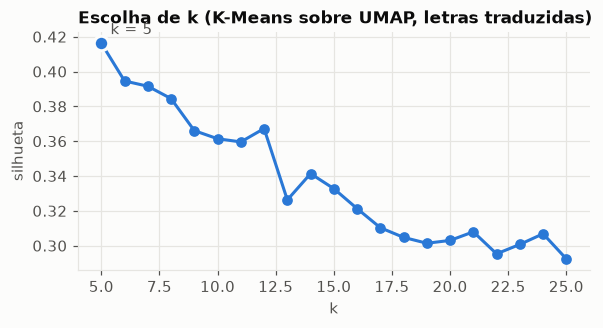

In [6]:
Z_p, lab_p, sil_p, info_p = reduz_e_agrupa(E_p)
K = info_p["k"]
faixas["cluster"] = lab_p
dados["cluster"] = dados["track_id"].map(faixas["cluster"])
print(f"versão {VERSAO} | K-Means / HDBSCAN:", info_p)

nmi_idioma = normalized_mutual_info_score(faixas["idioma"], lab_p)
nmi_pais = normalized_mutual_info_score(dados["cc"], dados["cluster"])
print(f"NMI(cluster, idioma) = {nmi_idioma:.3f} | NMI(cluster, país) = {nmi_pais:.3f}")
if nmi_idioma > 0.5:
    print("ATENÇÃO: os clusters estão muito associados ao idioma -> compare com a outra versão na seção 10.")

fig, ax = plt.subplots(figsize=(6, 2.8))
ax.plot(sil_p.index, sil_p.values, color=COR["s1"], marker="o")
ax.scatter([K], [sil_p[K]], s=90, color=COR["s1"], edgecolor=COR["fundo"], linewidth=2, zorder=3)
ax.annotate(f"k = {K}", (K, sil_p[K]), xytext=(6, 6), textcoords="offset points", color=COR["texto2"])
ax.set_xlabel("k"); ax.set_ylabel("silhueta"); ax.set_title(f"Escolha de k (K-Means sobre UMAP, letras {VERSAO}s)", loc="left")
fig.savefig(PASTA_RES / "silhueta.png"); plt.show()


,cluster,n_faixas,termos,idiomas,paises,exemplos
0,0,489,"don, love, want, time, feel, heart, tell, way, say, life","en 42%, es 37%, pt 20%","Austrália 25%, EUA 20%, México 20%","no tiene sentido (Beéle) · Ele É Ele, Eu Sou Eu (Wesley Safadão) · I Feel It Coming (T..."
1,1,151,"ain, don, bitch, niggas, fuck, shit, nigga, money, hit, make","en 90%, es 5%, pt 5%","EUA 56%, Austrália 31%, Brasil 4%",INDUSTRY BABY (feat. Jack Harlow) (Lil Nas X) · Swervin (feat. 6ix9ine) (A Boogie Wit ...
2,2,394,"don, want, going, love, come, baby, doesn, look, tell, little","es 47%, pt 41%, en 8%","Brasil 34%, Espanha 26%, México 23%",Bien Duro (C. Tangana) · Indeciso (Reik) · MERCHO (LiL CaKe)
3,3,185,"going, don, want, time, day, right, love, sure, think, away","ja 89%, pt 5%, es 5%","Japão 93%, Brasil 3%, México 3%",ロマンチシズム (Mrs. GREEN APPLE) · I’m invincible (Ado) · さよならの前に (AAA)
4,4,225,"don, baby, want, love, come, tell, going, time, night, make","es 48%, en 33%, pt 18%","Espanha 29%, México 22%, Austrália 16%",BRABA (Luísa Sonza) · Te Assumi Pro Brasil - Ao Vivo (Matheus) · A Gente Fez Amor - Ao...


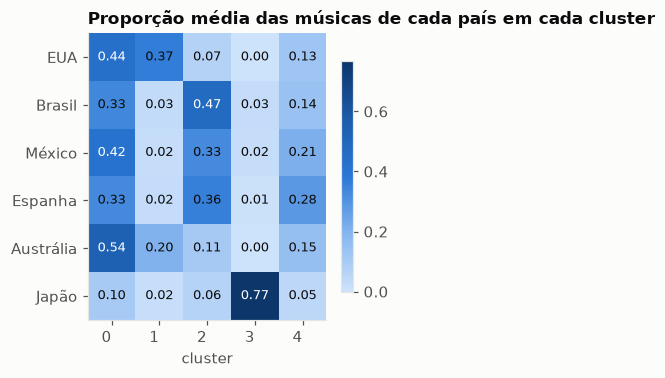

In [7]:
# interpretação: termos (c-TF-IDF por presença, usando a tradução quando existe), tamanho, idioma e país
# predominantes e as 3 músicas mais próximas do centro de cada cluster
texto_topicos = faixas["letra_en"].fillna(faixas["letra_limpa"])
topicos = tabela_clusters(faixas, dados, lab_p, Z_p, K, texto_topicos)
with pd.option_context("display.max_colwidth", 90):
    display(topicos)

# p_{a,t} médio: como cada país se distribui pelos clusters (média dos anos)
P_pais = (dados.groupby(["cc", "year"])["cluster"].value_counts(normalize=True).unstack(fill_value=0)
               .groupby(level="cc").mean().reindex(PAISES))
fig, ax = plt.subplots(figsize=(min(1.0 + 0.5 * K, 13), 3.4))
im = plota_matriz(P_pais, "Proporção média das músicas de cada país em cada cluster", ax, SEQ, vmin=0, fmt="{:.2f}")
ax.set_xticks(range(K), range(K), rotation=0); ax.set_xlabel("cluster")
fig.colorbar(im, ax=ax, shrink=0.8)
fig.savefig(PASTA_RES / "composicao_clusters.png"); plt.show()

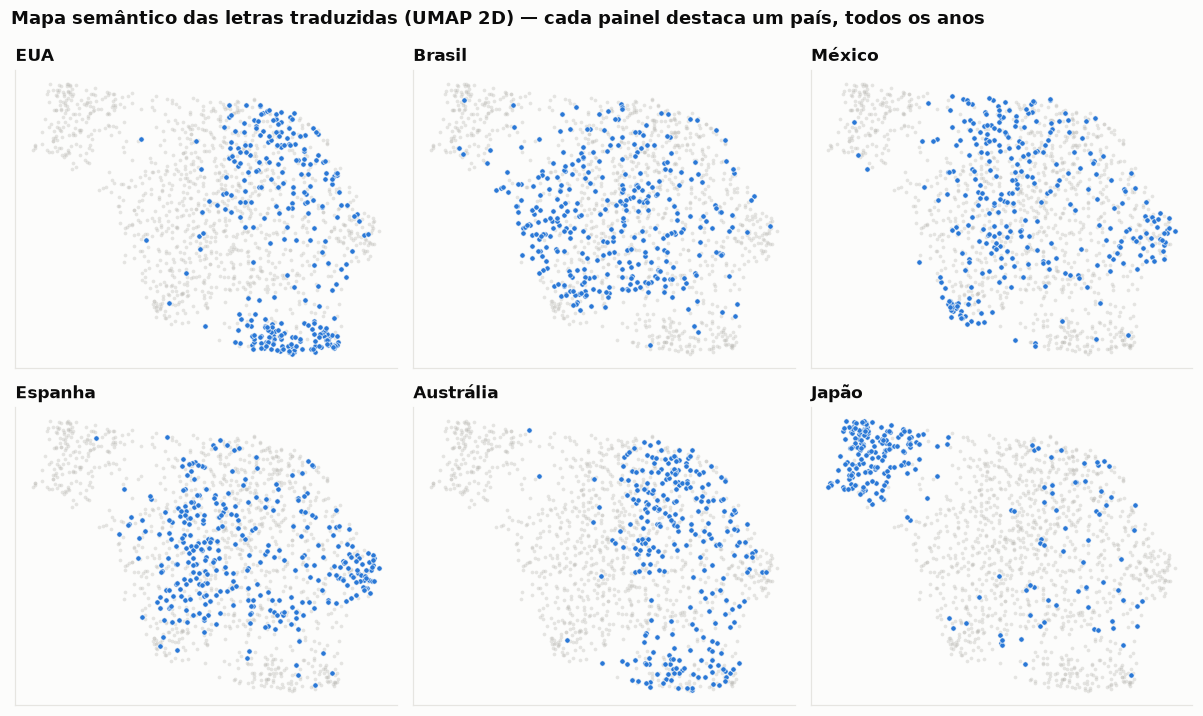

In [8]:
# mapa 2D (UMAP) — um painel por país, músicas do país em destaque sobre todas as outras
import umap
XY = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, metric="cosine", random_state=SEED).fit_transform(E_p)
fig, axes = plt.subplots(2, 3, figsize=(11, 6.6), sharex=True, sharey=True)
for ax, cc in zip(axes.flat, PAISES):
    ix = dados.loc[dados["cc"] == cc, "track_id"].map(POS).unique()
    ax.scatter(XY[:, 0], XY[:, 1], s=6, color=COR["neutro"], alpha=0.35, linewidth=0)
    ax.scatter(XY[ix, 0], XY[ix, 1], s=12, color=COR["s1"], edgecolor=COR["fundo"], linewidth=0.4)
    ax.set_title(NOMES[cc], loc="left"); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
fig.suptitle(f"Mapa semântico das letras {VERSAO}s (UMAP 2D) — cada painel destaca um país, todos os anos", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); fig.savefig(PASTA_RES / "mapa_umap_paises.png"); plt.show()

## 5. Similaridade cultural global $S_t$

$S_t$ = média, sobre os 15 pares de países, de $1 - JS(p_{a,t}, p_{b,t})$ (e do cosseno entre centroides). Faixa sombreada = IC 95% por bootstrap (reamostragem de músicas dentro de cada célula). Inclinação > 0 = convergência.
Só chamamos de tendência quando o IC bootstrap da inclinação exclui 0 **e** a regressão é significativa (p < 0,05); com 9 pontos, uma tendência só no bootstrap é marcada como "fraca".
Também reportamos a tendência **sem 2017**, ano atípico (Japão com ~74% das letras em inglês; ranking reconstruído de dados diários).

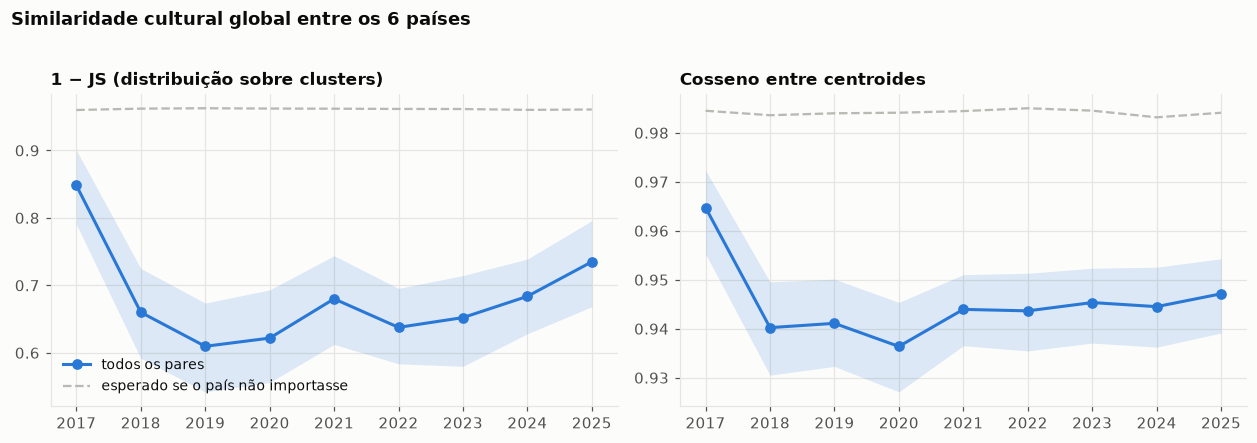

Tendência de S_t:


,serie,metrica,inclinacao_por_ano,ic95_lo,ic95_hi,p_regressao,spearman_rho,spearman_p,leitura
0,global,1−JS,-0.0047,-0.0127,0.0028,0.6502,0.1500,0.7001,sem tendência clara
1,global,cosseno,-0.0007,-0.0017,0.0004,0.5352,0.3167,0.4064,sem tendência clara
2,global sem 2017,1−JS,0.0112,0.0011,0.0210,0.0584,0.6429,0.0856,convergência fraca (só no bootstrap)
3,global sem 2017,cosseno,0.0011,-0.0002,0.0024,0.0199,0.8810,0.0039,sem tendência clara


Teste de permutação por ano (p pequeno = países mais diferentes que o acaso; S_rel < 1 = abaixo do acaso):


,ano,S_js,S_js_nulo,S_js_rel,p_js,S_cos,S_cos_nulo,S_cos_rel,p_cos
0,2017,0.8483,0.9599,0.8837,0.001,0.9647,0.9845,0.9799,0.001
1,2018,0.6601,0.9620,0.6862,0.001,0.9402,0.9836,0.9559,0.001
2,2019,0.6096,0.9625,0.6334,0.001,0.9411,0.9840,0.9564,0.001
3,2020,0.6218,0.9621,0.6463,0.001,0.9364,0.9841,0.9515,0.001
4,2021,0.6800,0.9619,0.7069,0.001,0.9440,0.9844,0.9589,0.001
5,2022,0.6377,0.9615,0.6632,0.001,0.9437,0.9850,0.9580,0.001
6,2023,0.6522,0.9614,0.6784,0.001,0.9453,0.9845,0.9602,0.001
7,2024,0.6837,0.9601,0.7121,0.001,0.9445,0.9832,0.9607,0.001
8,2025,0.7349,0.9607,0.7650,0.001,0.9471,0.9841,0.9624,0.001


In [9]:
res = serie_similaridade(dados, POS, lab_p, E_p, K)
serie_global, tend_global = resumo(res)
perm = permutacao(dados, POS, lab_p, E_p, K)

plota_series([("todos os pares", serie_global, COR["s1"])], "Similaridade cultural global entre os 6 países",
             "serie_St.png",
             ref={"js": (perm["ano"], perm["S_js_nulo"], "esperado se o país não importasse"),
                  "cos": (perm["ano"], perm["S_cos_nulo"], "esperado se o país não importasse")})

# sensibilidade: 2017 é atípico (Japão com 74% das letras em inglês; ranking reconstruído de dados diários)
sem17 = res["pr"]["ano"] != 2017
_, tend_global_s17 = resumo(res, sem17)
print("Tendência de S_t:")
display(tabela_tendencias({"global": tend_global, "global sem 2017": tend_global_s17}))
print("Teste de permutação por ano (p pequeno = países mais diferentes que o acaso; S_rel < 1 = abaixo do acaso):")
display(perm.round(4))

## 6. Pares de países e hipóteses H1 / H2

,par,media_js,media_cos,inclinacao_js,ic95_lo,ic95_hi,leitura
0,EUA–Brasil,0.6884,0.9415,0.0313,0.0123,0.0511,convergência
2,EUA–Espanha,0.7361,0.9555,0.0275,0.0061,0.0480,convergência
1,EUA–México,0.7372,0.9512,0.0151,-0.0047,0.0358,sem tendência clara
3,EUA–Austrália,0.9535,0.9883,0.0118,0.0006,0.0248,convergência fraca (só no bootstrap)
6,Brasil–Espanha,0.9270,0.9619,0.0105,-0.0000,0.0214,sem tendência clara
7,Brasil–Austrália,0.7958,0.9453,0.0075,-0.0085,0.0237,sem tendência clara
12,Espanha–Austrália,0.8353,0.9559,0.0060,-0.0105,0.0221,sem tendência clara
5,Brasil–México,0.9149,0.9580,0.0035,-0.0070,0.0146,sem tendência clara
9,México–Espanha,0.9490,0.9810,-0.0032,-0.0136,0.0069,sem tendência clara
10,México–Austrália,0.8466,0.9551,-0.0070,-0.0219,0.0082,sem tendência clara


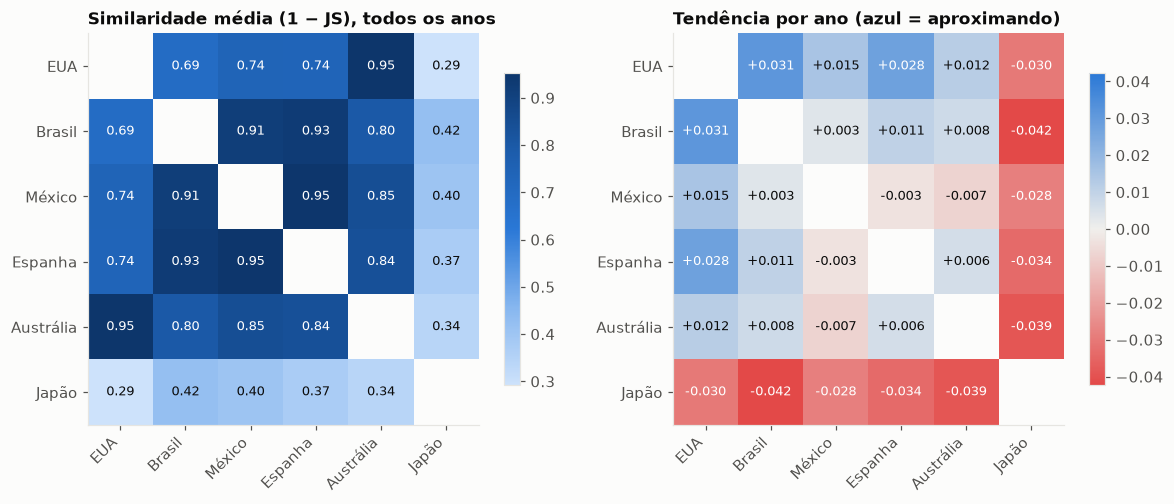

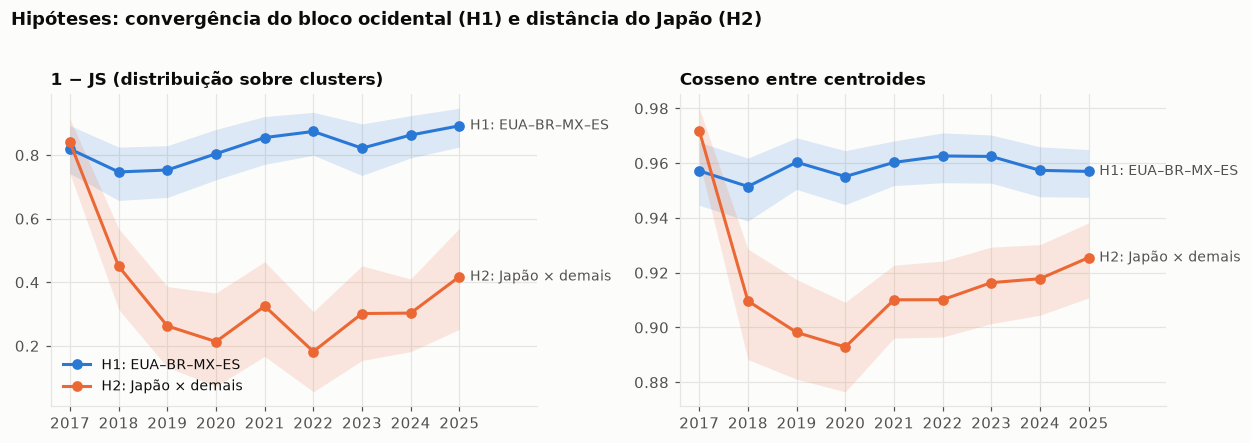

,serie,metrica,inclinacao_por_ano,ic95_lo,ic95_hi,p_regressao,spearman_rho,spearman_p,leitura
0,"H1 (pares entre EUA, BR, MX, ES)",1−JS,0.0141,0.0048,0.0227,0.0188,0.8167,0.0072,convergência
1,"H1 (pares entre EUA, BR, MX, ES)",cosseno,0.0005,-0.0008,0.0018,0.3391,0.2833,0.4600,sem tendência clara
2,H1 sem 2017,1−JS,0.0195,0.0077,0.0307,0.0047,0.8810,0.0039,convergência
3,H1 sem 2017,cosseno,0.0006,-0.0009,0.0021,0.3732,0.2619,0.5309,sem tendência clara
4,H2 (Japão com os demais),1−JS,-0.0347,-0.0512,-0.0185,0.1893,-0.2667,0.4879,divergência fraca (só no bootstrap)
5,H2 (Japão com os demais),cosseno,-0.0018,-0.0037,0.0001,0.5785,0.3333,0.3807,sem tendência clara
6,H2 sem 2017,1−JS,0.0012,-0.0210,0.0221,0.9427,0.0476,0.9108,sem tendência clara
7,H2 sem 2017,cosseno,0.0033,0.0008,0.0059,0.0242,0.9048,0.0020,convergência


In [10]:
pares = res["pares_df"]
linhas = []
for (a, b), g in pares.groupby(["a", "b"], sort=False):
    m = (res["pr"]["a"] == a) & (res["pr"]["b"] == b)
    _, t = resumo(res, m)
    linhas.append({"a": a, "b": b, "par": f"{NOMES[a]}–{NOMES[b]}", "media_js": g["sim_js"].mean(), "media_cos": g["sim_cos"].mean(),
                   "inclinacao_js": t["js"]["inclinacao_por_ano"], "ic95_lo": t["js"]["ic95_lo"], "ic95_hi": t["js"]["ic95_hi"],
                   "leitura": t["js"]["leitura"]})
tend_pares = pd.DataFrame(linhas).sort_values("inclinacao_js", ascending=False)
display(tend_pares.drop(columns=["a", "b"]).round(4))

def matriz(col):
    M = pd.DataFrame(np.nan, index=PAISES, columns=PAISES)
    for r in tend_pares.itertuples():
        M.loc[r.a, r.b] = M.loc[r.b, r.a] = getattr(r, col)
    return M

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
im0 = plota_matriz(matriz("media_js"), "Similaridade média (1 − JS), todos os anos", axes[0], SEQ)
fig.colorbar(im0, ax=axes[0], shrink=0.8)
Mi = matriz("inclinacao_js"); lim = np.nanmax(np.abs(Mi.values))
im1 = plota_matriz(Mi, "Tendência por ano (azul = aproximando)", axes[1], DIV, vmin=-lim, vmax=lim, fmt="{:+.3f}")
fig.colorbar(im1, ax=axes[1], shrink=0.8)
fig.tight_layout(); fig.savefig(PASTA_RES / "pares_paises.png"); plt.show()

# hipóteses
outros = [p for p in PAISES if p not in GRUPO_H2]
s_h1, t_h1 = resumo(res, mascara_pares(res, GRUPO_H1))
s_h2, t_h2 = resumo(res, mascara_pares(res, GRUPO_H2, outros))
plota_series([("H1: EUA–BR–MX–ES", s_h1, COR["s1"]), ("H2: Japão × demais", s_h2, COR["s2"])],
             "Hipóteses: convergência do bloco ocidental (H1) e distância do Japão (H2)", "hipoteses_H1_H2.png")
_, t_h1_s17 = resumo(res, mascara_pares(res, GRUPO_H1) & sem17)
_, t_h2_s17 = resumo(res, mascara_pares(res, GRUPO_H2, outros) & sem17)
display(tabela_tendencias({"H1 (pares entre EUA, BR, MX, ES)": t_h1, "H1 sem 2017": t_h1_s17,
                           "H2 (Japão com os demais)": t_h2, "H2 sem 2017": t_h2_s17}))

## 7. Grafo de países e comunidades (Louvain)

Com 6 países o Louvain sempre encontra algum bloco. Para saber se os blocos são reais, comparamos a
**modularidade Q** de cada ano com a de grafos montados depois de embaralhar os rótulos de país entre as músicas
(p pequeno = os blocos são mais fortes do que o acaso produz). A tendência de Q ao longo dos anos diz se os
blocos estão se separando (Q sobe) ou se misturando (Q cai).

Centralidade não é calculada aqui: num grafo de 6 nós ela não acrescenta nada. A versão com 37 países está em
`pipelineRedes.ipynb`.

,ano,n_comunidades,comunidades,Q,Q_nulo,Q_nulo_p95,p
0,2017,2,Brasil + México + Espanha + Austrália + Japão | EUA,0.0000,0.0918,0.2494,0.9441
1,2018,2,Brasil + Japão | EUA + México + Espanha + Austrália,0.0986,0.0937,0.2504,0.5968
2,2019,3,Brasil + México + Espanha | EUA + Austrália | Japão,0.0123,0.0889,0.2492,0.7066
3,2020,2,EUA + Brasil + México + Espanha + Austrália | Japão,-0.0000,0.0846,0.1820,0.9741
4,2021,3,Brasil + México + Espanha | EUA + Austrália | Japão,0.0025,0.0964,0.2506,0.7525
5,2022,3,Brasil + México + Espanha | EUA + Austrália | Japão,0.0070,0.0920,0.2505,0.7146
6,2023,3,Brasil + México + Espanha | EUA + Austrália | Japão,0.0059,0.0898,0.2489,0.7046
7,2024,2,EUA + Brasil + México + Espanha + Austrália | Japão,-0.0000,0.0841,0.1857,0.9960
8,2025,2,EUA + Brasil + México + Espanha + Austrália | Japão,-0.0000,0.0901,0.2495,0.9960


Tendência de Q: -0.0050/ano (p da regressão = 0.248) | Q acima do nulo (p<0,05) em 0 de 9 anos


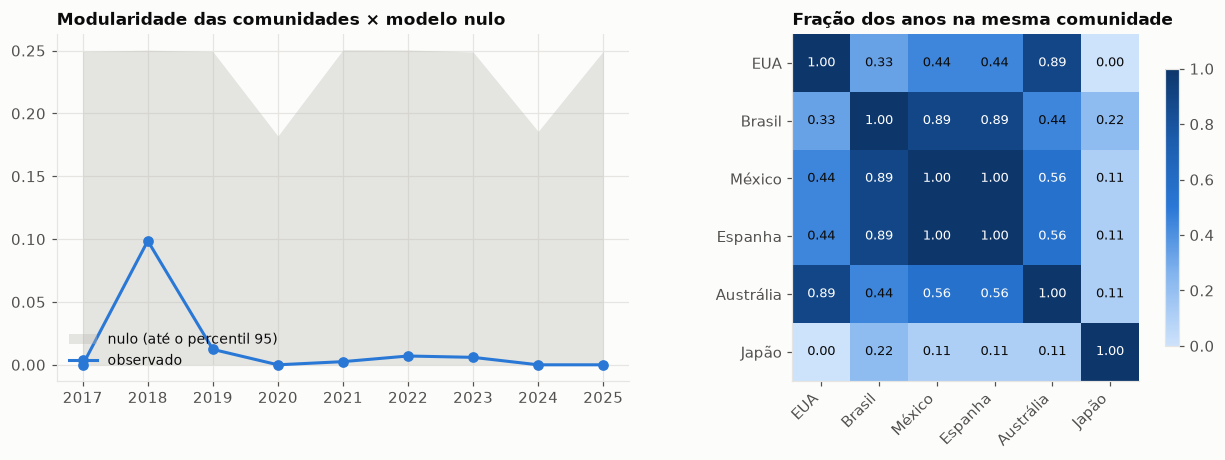

In [11]:
com_ano, junto = comunidades(pares)
modq = modularidade_nulo(dados, POS, lab_p, E_p, K)
com_ano = com_ano.merge(modq, on="ano")
with pd.option_context("display.max_colwidth", 120):
    display(com_ano.round(4))
reg_q = linregress(modq["ano"], modq["Q"])
print(f"Tendência de Q: {reg_q.slope:+.4f}/ano (p da regressão = {reg_q.pvalue:.3f}) | "
      f"Q acima do nulo (p<0,05) em {(modq['p'] < 0.05).sum()} de {len(modq)} anos")

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), gridspec_kw={"width_ratios": [1.1, 1]})
ax = axes[0]
ax.fill_between(modq["ano"], 0, modq["Q_nulo_p95"], color=COR["neutro"], alpha=0.35, linewidth=0, label="nulo (até o percentil 95)")
ax.plot(modq["ano"], modq["Q"], color=COR["s1"], marker="o", label="observado")
ax.set_xticks(modq["ano"]); ax.legend(fontsize=9, loc="lower left")
ax.set_title("Modularidade das comunidades × modelo nulo", loc="left")
im = plota_matriz(junto, "Fração dos anos na mesma comunidade", axes[1], SEQ, vmin=0, vmax=1)
fig.colorbar(im, ax=axes[1], shrink=0.8)
fig.tight_layout(); fig.savefig(PASTA_RES / "comunidades.png"); plt.show()


## 8. Controle: músicas compartilhadas × exclusivas

Uma música é *compartilhada* num ano se aparece no top 40 de 2+ países naquele ano (comparando por título + artista principal, não por `track_id`, que muda entre versões). Se a convergência some quando só as exclusivas são usadas, ela é explicada pelos hits globais.

,pct_compartilhadas,musicas_em_2mais,musicas_em_4mais
year,,,
2017,52.1,49,6
2018,36.4,39,3
2019,35.8,38,3
2020,31.2,32,3
2021,30.5,34,1
2022,27.9,31,1
2023,25.8,30,1
2024,22.9,27,0
2025,26.2,29,1


músicas exclusivas por célula:


year,2017,2018,2019,2020,2021,2022,2023,2024,2025
cc,,,,,,,,,
au,12,14,14,16,17,23,22,19,16
br,34,38,37,35,38,39,39,39,38
es,12,23,26,29,28,27,30,34,35
jp,23,38,38,39,40,39,40,40,38
mx,12,23,24,27,27,25,27,34,36
us,21,16,15,19,16,20,20,19,14


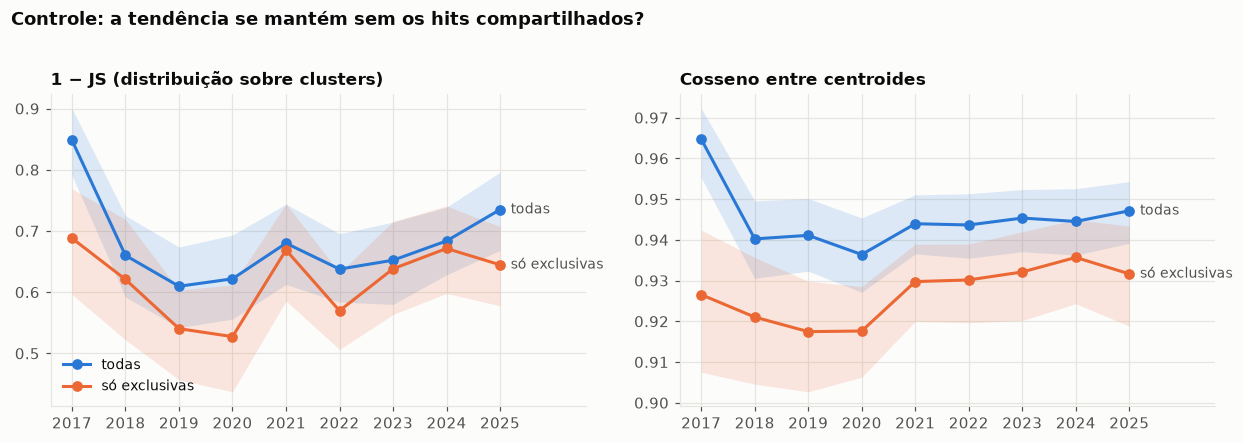

,serie,metrica,inclinacao_por_ano,ic95_lo,ic95_hi,p_regressao,spearman_rho,spearman_p,leitura
0,todas,1−JS,-0.0047,-0.0127,0.0028,0.6502,0.1500,0.7001,sem tendência clara
1,todas,cosseno,-0.0007,-0.0017,0.0004,0.5352,0.3167,0.4064,sem tendência clara
2,só exclusivas,1−JS,0.0036,-0.0061,0.0133,0.6691,0.1333,0.7324,sem tendência clara
3,só exclusivas,cosseno,0.0018,-0.0000,0.0037,0.0264,0.8000,0.0096,sem tendência clara


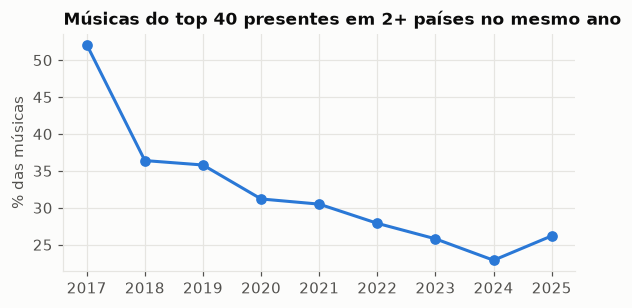

In [12]:
n_paises = dados.groupby(["year", "chave"])["cc"].transform("nunique")
dados["compartilhada"] = n_paises >= 2
comp = dados.groupby("year").agg(pct_compartilhadas=("compartilhada", "mean"),
                                 musicas_em_2mais=("chave", lambda s: s[dados.loc[s.index, "compartilhada"]].nunique()))
comp["musicas_em_4mais"] = dados[n_paises >= 4].groupby("year")["chave"].nunique().reindex(comp.index, fill_value=0)
comp["pct_compartilhadas"] = (comp["pct_compartilhadas"] * 100).round(1)
display(comp)

excl = dados[~dados["compartilhada"]]
excl = excl[excl.groupby(["cc", "year"])["track_id"].transform("size") >= MIN_CELULA]
print("músicas exclusivas por célula:")
display(excl.groupby(["cc", "year"]).size().unstack())
res_excl = serie_similaridade(excl, POS, lab_p, E_p, K)
serie_excl, tend_excl = resumo(res_excl)
plota_series([("todas", serie_global, COR["s1"]), ("só exclusivas", serie_excl, COR["s2"])],
             "Controle: a tendência se mantém sem os hits compartilhados?", "controle_exclusivas.png")
display(tabela_tendencias({"todas": tend_global, "só exclusivas": tend_excl}))

fig, ax = plt.subplots(figsize=(6, 2.8))
ax.plot(comp.index, comp["pct_compartilhadas"], color=COR["s1"], marker="o")
ax.set_xticks(comp.index); ax.set_ylabel("% das músicas")
ax.set_title("Músicas do top 40 presentes em 2+ países no mesmo ano", loc="left")
fig.savefig(PASTA_RES / "pct_compartilhadas.png"); plt.show()

## 9. Estratificação por idioma

Composição de idiomas por célula. Mudanças de composição (ex.: mais músicas em inglês no Japão) podem, sozinhas, mover $S_t$.

In [13]:
comp_idioma = (pd.crosstab([dados["cc"], dados["year"]], dados["idioma"], normalize="index") * 100).round(0)
display(comp_idioma)

idioma      en     es    ja   ko  outro    pt
cc year                                      
au 2017   98.0    2.0   0.0  0.0    0.0   0.0
   2018  100.0    0.0   0.0  0.0    0.0   0.0
   2019  100.0    0.0   0.0  0.0    0.0   0.0
   2020  100.0    0.0   0.0  0.0    0.0   0.0
   2021  100.0    0.0   0.0  0.0    0.0   0.0
   2022  100.0    0.0   0.0  0.0    0.0   0.0
   2023  100.0    0.0   0.0  0.0    0.0   0.0
   2024  100.0    0.0   0.0  0.0    0.0   0.0
   2025  100.0    0.0   0.0  0.0    0.0   0.0
br 2017   15.0    3.0   0.0  0.0    0.0  82.0
   2018    5.0    3.0   0.0  0.0    0.0  92.0
   2019    8.0    2.0   0.0  0.0    0.0  90.0
   2020   12.0    2.0   0.0  0.0    0.0  85.0
   2021    5.0    0.0   0.0  0.0    0.0  95.0
   2022    2.0    0.0   0.0  0.0    0.0  98.0
   2023    2.0    0.0   0.0  0.0    0.0  98.0
   2024    2.0    0.0   0.0  0.0    0.0  98.0
   2025    5.0    0.0   0.0  0.0    0.0  95.0
es 2017   20.0   80.0   0.0  0.0    0.0   0.0
   2018   20.0   80.0   0.0  0.0    0.0   0.0
   2019    8.0   92.0   0.0  0.0    0.0   0.0
   2020    8.0   92.0   0.0  0.0    0.0   0.0
   2021    5.0   95.0   0.0  0.0    0.0   0.0
   2022    0.0  100.0   0.0  0.0    0.0   0.0
   2023    0.0  100.0   0.0  0.0    0.0   0.0
   2024    2.0   95.0   0.0  0.0    2.0   0.0
   2025    2.0   98.0   0.0  0.0    0.0   0.0
jp 2017   74.0    3.0  21.0  3.0    0.0   0.0
   2018   22.0    0.0  75.0  2.0    0.0   0.0
   2019    8.0    0.0  92.0  0.0    0.0   0.0
   2020    8.0    0.0  92.0  0.0    0.0   0.0
   2021    8.0    0.0  85.0  2.0    5.0   0.0
   2022    8.0    0.0  92.0  0.0    0.0   0.0
   2023   12.0    0.0  88.0  0.0    0.0   0.0
   2024    8.0    0.0  90.0  0.0    2.0   0.0
   2025   12.0    0.0  88.0  0.0    0.0   0.0
mx 2017   18.0   82.0   0.0  0.0    0.0   0.0
   2018   12.0   88.0   0.0  0.0    0.0   0.0
   2019   20.0   80.0   0.0  0.0    0.0   0.0
   2020   12.0   88.0   0.0  0.0    0.0   0.0
   2021    5.0   95.0   0.0  0.0    0.0   0.0
   2022    2.0   98.0   0.0  0.0    0.0   0.0
   2023    2.0   98.0   0.0  0.0    0.0   0.0
   2024    0.0  100.0   0.0  0.0    0.0   0.0
   2025    0.0  100.0   0.0  0.0    0.0   0.0
us 2017   98.0    2.0   0.0  0.0    0.0   0.0
   2018   98.0    2.0   0.0  0.0    0.0   0.0
   2019  100.0    0.0   0.0  0.0    0.0   0.0
   2020  100.0    0.0   0.0  0.0    0.0   0.0
   2021   95.0    5.0   0.0  0.0    0.0   0.0
   2022   92.0    8.0   0.0  0.0    0.0   0.0
   2023   95.0    5.0   0.0  0.0    0.0   0.0
   2024  100.0    0.0   0.0  0.0    0.0   0.0
   2025   98.0    2.0   0.0  0.0    0.0   0.0

## 10. Comparação: letra original × traduzida

Refaz clusters e tendências nas duas versões, **no mesmo conjunto de faixas e países**. Se uma conclusão só aparece com a letra original, ela reflete **idioma**, não conteúdo; se só aparece com a traduzida, o idioma estava escondendo uma semelhança de conteúdo. As tabelas de clusters das duas versões são salvas em `clusters_topicos_original.csv` e `clusters_topicos_traduzida.csv`.
Só entram países com tradução suficiente (`MIN_CELULA`) em todos os anos — se o conjunto de pares mudasse entre anos, a tendência ficaria contaminada.

cobertura da tradução por célula (%):


year,2017,2018,2019,2020,2021,2022,2023,2024,2025
cc,,,,,,,,,
au,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
br,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
es,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
jp,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
mx,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
us,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0


países na comparação: ['EUA', 'Brasil', 'México', 'Espanha', 'Austrália', 'Japão']
[traducao_en] 1444 embeddings lidos do cache dados/embeddings/sentence_transformers_LaBSE__traducao_en.npz


original: k=5 | silhueta=0.484 | NMI(cluster, idioma) = 0.519


traduzida: k=5 | silhueta=0.416 | NMI(cluster, idioma) = 0.295


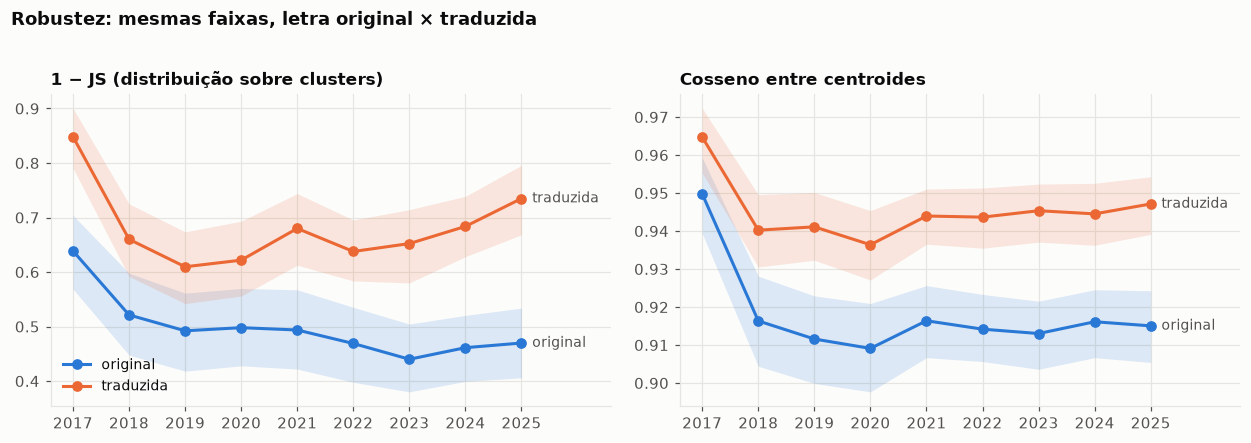

,serie,metrica,inclinacao_por_ano,ic95_lo,ic95_hi,p_regressao,spearman_rho,spearman_p,leitura
0,original: global,1−JS,-0.0165,-0.0250,-0.0077,0.0130,-0.8333,0.0053,divergência
1,original: global,cosseno,-0.0022,-0.0034,-0.0008,0.1772,-0.2333,0.5457,divergência fraca (só no bootstrap)
2,original: global sem 2017,1−JS,-0.0085,-0.0191,0.0021,0.0132,-0.7619,0.0280,sem tendência clara
3,original: global sem 2017,cosseno,0.0003,-0.0013,0.0019,0.5359,0.0952,0.8225,sem tendência clara
4,original: H1,1−JS,0.0029,-0.0076,0.0148,0.6111,0.0000,1.0000,sem tendência clara
5,original: H1,cosseno,-0.0008,-0.0021,0.0007,0.1814,-0.3500,0.3558,sem tendência clara
6,original: H1 sem 2017,1−JS,0.0045,-0.0089,0.0191,0.5365,0.0714,0.8665,sem tendência clara
7,original: H1 sem 2017,cosseno,-0.0007,-0.0022,0.0010,0.3413,-0.2857,0.4927,sem tendência clara
8,original: H2,1−JS,-0.0405,-0.0543,-0.0257,0.0087,-0.8500,0.0037,divergência
9,original: H2,cosseno,-0.0043,-0.0068,-0.0016,0.3414,0.0667,0.8647,divergência fraca (só no bootstrap)


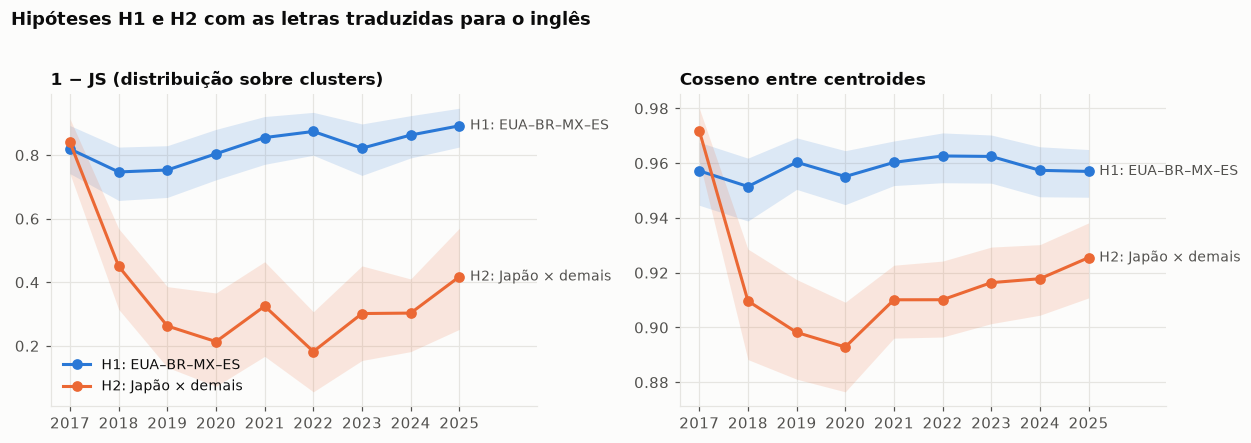

concordância das séries (js): Spearman rho = 0.17 (p = 0.668)
concordância das séries (cos): Spearman rho = 0.50 (p = 0.170)


In [14]:
tem = faixas["letra_en"].notna()
cob = dados.assign(t=dados["track_id"].map(tem)).groupby(["cc", "year"])["t"].mean().unstack()
print("cobertura da tradução por célula (%):")
display((cob * 100).round(0))

rob = {}
if tem.sum() < 200:
    print(f"só {tem.sum()} faixas traduzidas — rode de novo quando a tradução estiver completa.")
else:
    fx = faixas[tem]
    pos_sub = {t: i for i, t in enumerate(fx.index)}
    d_sub = dados[dados["track_id"].isin(fx.index)]
    d_sub = d_sub[d_sub.groupby(["cc", "year"])["track_id"].transform("size") >= MIN_CELULA]
    # só países com todos os anos: se o conjunto de pares muda entre anos, a tendência de S_t fica contaminada
    n_anos = dados["year"].nunique()
    completos = [c for c in PAISES if d_sub.loc[d_sub["cc"] == c, "year"].nunique() == n_anos]
    fora = [c for c in PAISES if c not in completos]
    d_sub = d_sub[d_sub["cc"].isin(completos)]
    print("países na comparação:", [NOMES[c] for c in completos])
    if fora:
        print("fora por falta de tradução em algum ano:", [NOMES[c] for c in fora], "-> rode de novo quando a tradução terminar")
    E_en = gera_embeddings(fx["letra_en"], "traducao_en")
    excl_sub = d_sub[~d_sub["compartilhada"]]
    excl_sub = excl_sub[excl_sub.groupby(["cc", "year"])["track_id"].transform("size") >= MIN_CELULA]
    outros_sub = [p for p in completos if p not in GRUPO_H2]
    for nome, E_ in [("original", E_orig[[POS[t] for t in fx.index]]), ("traduzida", E_en)]:
        Z_, lab, _, info = reduz_e_agrupa(E_)
        tabela_clusters(fx, d_sub, lab, Z_, info["k"], fx["letra_en"].fillna(fx["letra_limpa"])).to_csv(
            PASTA_RES / f"clusters_topicos_{nome}.csv", index=False)
        r = serie_similaridade(d_sub, pos_sub, lab, E_, info["k"])
        s17 = r["pr"]["ano"] != 2017
        s, t = resumo(r)
        rob[nome] = {"serie": s, "tend": t, "info": info, "res": r,
                     "nmi_idioma": normalized_mutual_info_score(fx["idioma"], lab),
                     "tend_s17": resumo(r, s17)[1]}
        if set(GRUPO_H1) <= set(completos):
            rob[nome]["h1"] = resumo(r, mascara_pares(r, GRUPO_H1))
            rob[nome]["h1_s17"] = resumo(r, mascara_pares(r, GRUPO_H1) & s17)[1]
        if set(GRUPO_H2) <= set(completos):
            rob[nome]["h2"] = resumo(r, mascara_pares(r, GRUPO_H2, outros_sub))
            rob[nome]["h2_s17"] = resumo(r, mascara_pares(r, GRUPO_H2, outros_sub) & s17)[1]
        r_ex = serie_similaridade(excl_sub, pos_sub, lab, E_, info["k"])
        rob[nome]["excl"] = resumo(r_ex)[1]
        # controle das hipóteses: só músicas exclusivas de cada país
        if set(GRUPO_H1) <= set(completos):
            rob[nome]["h1_excl"] = resumo(r_ex, mascara_pares(r_ex, GRUPO_H1))[1]
        if set(GRUPO_H2) <= set(completos):
            rob[nome]["h2_excl"] = resumo(r_ex, mascara_pares(r_ex, GRUPO_H2, outros_sub))[1]
        print(f"{nome}: k={info['k']} | silhueta={info['silhueta']} | NMI(cluster, idioma) = {rob[nome]['nmi_idioma']:.3f}")
    plota_series([("original", rob["original"]["serie"], COR["s1"]), ("traduzida", rob["traduzida"]["serie"], COR["s2"])],
                 "Robustez: mesmas faixas, letra original × traduzida", "robustez_traducao.png")
    tabs = {}
    for nome in ["original", "traduzida"]:
        v = rob[nome]
        tabs[f"{nome}: global"] = v["tend"]
        tabs[f"{nome}: global sem 2017"] = v["tend_s17"]
        if "h1" in v:
            tabs[f"{nome}: H1"] = v["h1"][1]; tabs[f"{nome}: H1 sem 2017"] = v["h1_s17"]
        if "h2" in v:
            tabs[f"{nome}: H2"] = v["h2"][1]; tabs[f"{nome}: H2 sem 2017"] = v["h2_s17"]
        tabs[f"{nome}: só exclusivas"] = v["excl"]
        if "h1_excl" in v:
            tabs[f"{nome}: H1 só exclusivas"] = v["h1_excl"]
        if "h2_excl" in v:
            tabs[f"{nome}: H2 só exclusivas"] = v["h2_excl"]
    tab_rob = tabela_tendencias(tabs)
    display(tab_rob)
    if "h1" in rob["traduzida"] and "h2" in rob["traduzida"]:
        plota_series([("H1: EUA–BR–MX–ES", rob["traduzida"]["h1"][0], COR["s1"]),
                      ("H2: Japão × demais", rob["traduzida"]["h2"][0], COR["s2"])],
                     "Hipóteses H1 e H2 com as letras traduzidas para o inglês", "hipoteses_H1_H2_traduzida.png")
    for met in ["js", "cos"]:
        rho, p = spearmanr(rob["original"]["serie"][met], rob["traduzida"]["serie"][met])
        print(f"concordância das séries ({met}): Spearman rho = {rho:.2f} (p = {p:.3f})")

## 11. Robustez do H1

O H1 (convergência entre EUA, BR, MX e ES) é o resultado central, então ele passa por quatro testes que poderiam derrubá-lo:

1. **Sementes e k.** O 1−JS depende dos clusters, e o K-Means com k escolhido pela silhueta é instável (o HDBSCAN encontra outro número de grupos). Refazemos UMAP + K-Means com 5 sementes × 4 valores de k (20 partições). Se o H1 só aparece numa partição, ele é artefato dela.
2. **Composição de idiomas fixa.** Mesmo com a letra traduzida, se a fatia de músicas em inglês nos charts de BR/MX/ES mudou ao longo dos anos, essa mudança sozinha pode produzir "convergência". Cada música recebe um peso que faz a composição de idiomas de cada país ficar **igual em todos os anos** (a média do país no período): peso = participação média do idioma no país ÷ participação do idioma naquele ano. Um idioma ausente num ano não pode ser compensado; nesse caso, os pesos são renormalizados.
3. **Só músicas no idioma local** (inglês para EUA, português para BR, espanhol para MX e ES): a produção local de cada país está ficando parecida em conteúdo? É a versão mais exigente: elimina a importação de hits estrangeiros.
4. **As duas métricas lado a lado:** 1−JS (depende dos clusters) e cosseno entre centroides (não depende).

O bootstrap aqui usa `N_BOOT_ROB` réplicas (padrão 300) para caber num tempo razoável com 20 partições.


semente 42: ok


semente 7: ok


semente 123: ok


semente 2024: ok


semente 99: ok
H1 (1−JS) em 5 sementes × 4 valores de k:


,particoes,convergencia,convergencia_fraca,sem_tendencia,divergencia,inclinacao_mediana,inclinacao_min,inclinacao_max
amostra,,,,,,,,
só exclusivas,20,19,1,0,0,0.0216,0.0166,0.0280
todas,20,5,3,12,0,0.0092,0.0002,0.0163


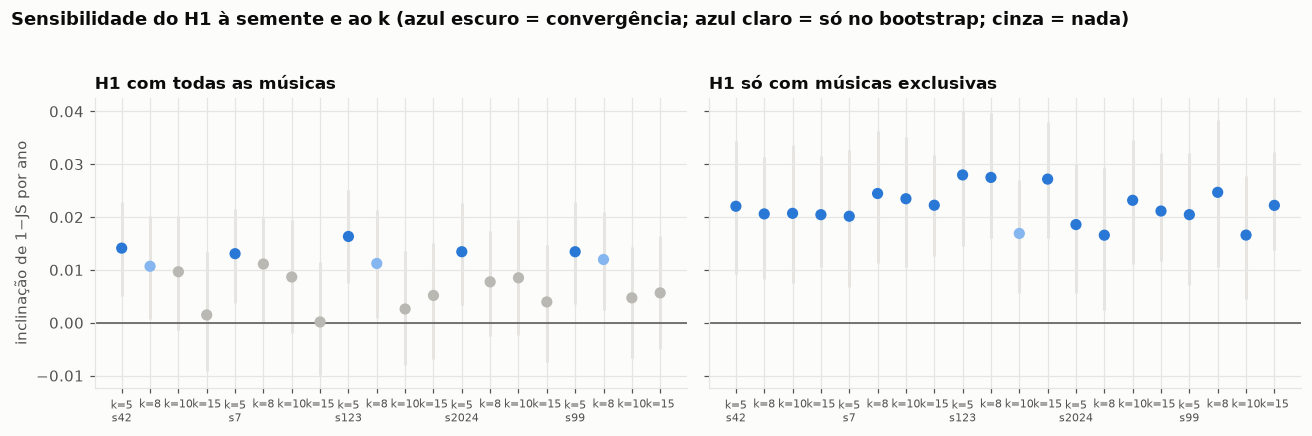

Participação de músicas em inglês por país e ano (%) e tendência:


year,2017,2018,2019,2020,2021,2022,2023,2024,2025,tendência (pp/ano)
cc,,,,,,,,,,
us,98.0,98.0,100.0,100.0,95.0,92.0,95.0,100.0,98.0,-0.17
br,15.0,5.0,8.0,12.0,5.0,2.0,2.0,2.0,5.0,-1.16
mx,18.0,12.0,20.0,12.0,5.0,2.0,2.0,0.0,0.0,-2.54
es,20.0,20.0,8.0,8.0,5.0,0.0,0.0,2.0,2.0,-2.42
au,98.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,0.17
jp,74.0,22.0,8.0,8.0,8.0,8.0,12.0,8.0,12.0,-4.71


músicas no idioma local por célula:


year,2017,2018,2019,2020,2021,2022,2023,2024,2025
cc,,,,,,,,,
au,39.0,40.0,40.0,40.0,40.0,40.0,40.0,40.0,40.0
br,32.0,36.0,36.0,34.0,38.0,39.0,39.0,39.0,38.0
es,32.0,32.0,37.0,37.0,38.0,40.0,40.0,38.0,39.0
jp,NaN,30.0,37.0,37.0,34.0,37.0,35.0,36.0,35.0
mx,33.0,35.0,32.0,35.0,38.0,39.0,39.0,40.0,40.0
us,39.0,39.0,40.0,40.0,37.0,37.0,38.0,40.0,39.0


Sementes × k (1−JS, todas as músicas): convergência em 5 de 20 partições; inclinação de +0.0002 a +0.0163
Sementes × k (1−JS, só exclusivas):     convergência em 19 de 20 partições; inclinação de +0.0166 a +0.0280


,variante,1−JS inclinação,1−JS IC95,1−JS p,1−JS leitura,cosseno inclinação,cosseno IC95,cosseno p,cosseno leitura,obs
0,base (traduzida),0.0141,"[+0.0048, +0.0227]",0.0188,convergência,0.0005,"[-0.0008, +0.0018]",0.3391,sem tendência clara,
1,sem 2017,0.0195,"[+0.0077, +0.0307]",0.0047,convergência,0.0006,"[-0.0009, +0.0021]",0.3732,sem tendência clara,
2,só exclusivas,0.0220,"[+0.0096, +0.0348]",0.0137,convergência,0.0039,"[+0.0016, +0.0063]",0.0018,convergência,
3,composição de idiomas fixa,0.0161,"[+0.0065, +0.0253]",0.0072,convergência,0.0012,"[-0.0001, +0.0025]",0.0560,sem tendência clara,
4,só idioma local,0.0173,"[+0.0066, +0.0274]",0.0082,convergência,0.0016,"[+0.0002, +0.0030]",0.0139,convergência,1984 linhas
5,"só idioma local, sem 2017",0.0217,"[+0.0090, +0.0340]",0.0057,convergência,0.0015,"[+0.0001, +0.0031]",0.0533,convergência fraca (só no bootstrap),
6,versão original (comparação),0.0029,"[-0.0076, +0.0148]",0.6111,sem tendência clara,-0.0008,"[-0.0021, +0.0007]",0.1814,sem tendência clara,


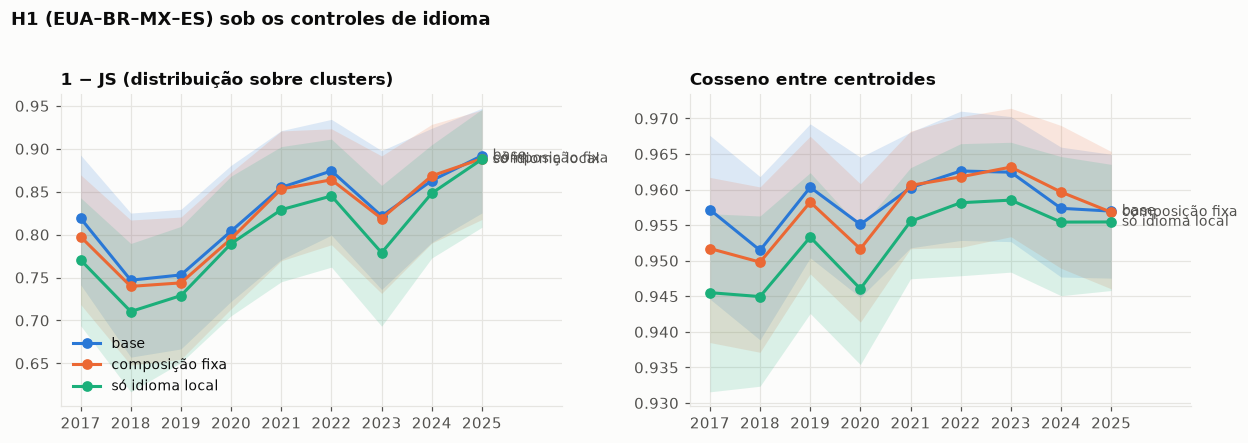

In [15]:
N_BOOT_ROB = int(os.environ.get("N_BOOT_ROB", 300))
SEMENTES   = [SEED, 7, 123, 2024, 99]
KS         = [5, 8, 10, 15]
LINGUA_LOCAL = {"us": "en", "au": "en", "br": "pt", "mx": "es", "es": "es", "jp": "ja"}

def h1(r, mascara=None):
    m = mascara_pares(r, GRUPO_H1)
    if mascara is not None:
        m = m & mascara
    return resumo(r, m)

def linha_painel(nome, tend, obs=""):
    l = {"variante": nome}
    for met, rot in [("js", "1−JS"), ("cos", "cosseno")]:
        t = tend[met]
        l.update({f"{rot} inclinação": t["inclinacao_por_ano"], f"{rot} IC95": f"[{t['ic95_lo']:+.4f}, {t['ic95_hi']:+.4f}]",
                  f"{rot} p": t["p_regressao"], f"{rot} leitura": t["leitura"]})
    l["obs"] = obs
    return l

# ---------- 1. sementes × k
import umap
sens = []
for s in SEMENTES:
    Zs = umap.UMAP(n_components=UMAP_DIM, n_neighbors=15, min_dist=0.0, metric="cosine", random_state=s).fit_transform(E_p)
    for k in KS:
        lab = KMeans(k, n_init=10, random_state=s).fit_predict(Zs)
        for amostra, d_ in [("todas", dados), ("só exclusivas", excl)]:
            _, t = h1(serie_similaridade(d_, POS, lab, E_p, k, n_boot=N_BOOT_ROB))
            t = t["js"]
            sens.append({"semente": s, "k": k, "amostra": amostra, "inclinacao": t["inclinacao_por_ano"],
                         "ic95_lo": t["ic95_lo"], "ic95_hi": t["ic95_hi"], "p": t["p_regressao"], "leitura": t["leitura"]})
    print(f"semente {s}: ok")
sens = pd.DataFrame(sens)
res_sens = sens.groupby("amostra").agg(particoes=("k", "size"),
                                       convergencia=("leitura", lambda x: (x == "convergência").sum()),
                                       convergencia_fraca=("leitura", lambda x: x.str.startswith("convergência fraca").sum()),
                                       sem_tendencia=("leitura", lambda x: (x == "sem tendência clara").sum()),
                                       divergencia=("leitura", lambda x: x.str.startswith("divergência").sum()),
                                       inclinacao_mediana=("inclinacao", "median"),
                                       inclinacao_min=("inclinacao", "min"), inclinacao_max=("inclinacao", "max"))
print(f"H1 (1−JS) em {len(SEMENTES)} sementes × {len(KS)} valores de k:")
display(res_sens.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, amostra in zip(axes, ["todas", "só exclusivas"]):
    g = sens[sens["amostra"] == amostra].reset_index(drop=True)
    x = np.arange(len(g))
    cor = np.where(g["leitura"] == "convergência", COR["s1"], np.where(g["ic95_lo"] > 0, "#86b6ef", COR["neutro"]))
    ax.errorbar(x, g["inclinacao"], yerr=[g["inclinacao"] - g["ic95_lo"], g["ic95_hi"] - g["inclinacao"]],
                fmt="none", ecolor=COR["grade"], elinewidth=2)
    ax.scatter(x, g["inclinacao"], c=cor, s=40, zorder=3)
    ax.axhline(0, color=COR["texto2"], linewidth=1)
    ax.set_xticks(x, [f"k={k}\ns{s}" if i % len(KS) == 0 else f"k={k}" for i, (s, k) in enumerate(zip(g["semente"], g["k"]))],
                  fontsize=7)
    ax.set_title(f"H1 com {amostra} as músicas" if amostra == "todas" else "H1 só com músicas exclusivas", loc="left")
axes[0].set_ylabel("inclinação de 1−JS por ano")
fig.suptitle("Sensibilidade do H1 à semente e ao k (azul escuro = convergência; azul claro = só no bootstrap; cinza = nada)",
             x=0.01, ha="left", fontweight="bold", y=1.03)
fig.tight_layout(); fig.savefig(PASTA_RES / "robustez_H1_sementes.png"); plt.show()

# ---------- 2. composição de idiomas fixa
comp_ano = pd.crosstab([dados["cc"], dados["year"]], dados["idioma"], normalize="index")
alvo = comp_ano.groupby(level="cc").mean()
obs_ = comp_ano.stack().rename("obs")
alv_ = alvo.stack().rename("alvo")
pesos = dados[["cc", "year", "idioma"]].join(obs_, on=["cc", "year", "idioma"]).join(alv_, on=["cc", "idioma"])
dados["peso_idioma"] = (pesos["alvo"] / pesos["obs"]).to_numpy()
ing = (comp_ano["en"] if "en" in comp_ano else pd.Series(0, index=comp_ano.index)).unstack("year")
print("Participação de músicas em inglês por país e ano (%) e tendência:")
tab_ing = (ing * 100).round(0)
tab_ing["tendência (pp/ano)"] = [linregress(ing.columns.astype(float), ing.loc[c].values).slope * 100 for c in ing.index]
display(tab_ing.loc[[c for c in PAISES if c in tab_ing.index]].round(2))
res_comp = serie_similaridade(dados, POS, lab_p, E_p, K, peso="peso_idioma")

# ---------- 3. só o idioma local
local = dados[dados["idioma"] == dados["cc"].map(LINGUA_LOCAL)]
local = local[local.groupby(["cc", "year"])["track_id"].transform("size") >= MIN_CELULA]
print("músicas no idioma local por célula:")
display(local.groupby(["cc", "year"]).size().unstack())
anos_ok = local.groupby("year")["cc"].apply(lambda s: set(GRUPO_H1) <= set(s))
if not anos_ok.all():
    print("anos sem os 4 países do H1 com músicas locais suficientes (ficam fora):", list(anos_ok[~anos_ok].index))
local = local[local["year"].isin(anos_ok[anos_ok].index)]
res_local = serie_similaridade(local, POS, lab_p, E_p, K)

# ---------- 4. painel: as duas métricas em todas as variantes
sem17 = res["pr"]["ano"] != 2017
painel = [linha_painel(f"base ({VERSAO})", h1(res)[1]),
          linha_painel("sem 2017", h1(res, sem17)[1]),
          linha_painel("só exclusivas", h1(res_excl)[1]),
          linha_painel("composição de idiomas fixa", h1(res_comp)[1]),
          linha_painel("só idioma local", h1(res_local)[1], f"{len(local)} linhas"),
          linha_painel("só idioma local, sem 2017", h1(res_local, res_local["pr"]["ano"] != 2017)[1])]
if rob:
    outra = "original" if VERSAO == "traduzida" else "traduzida"
    if "h1" in rob.get(outra, {}):
        painel.append(linha_painel(f"versão {outra} (comparação)", rob[outra]["h1"][1]))
painel = pd.DataFrame(painel)
r_ = res_sens.loc["todas"]
print(f"Sementes × k (1−JS, todas as músicas): convergência em {int(r_['convergencia'])} de {int(r_['particoes'])} partições; "
      f"inclinação de {r_['inclinacao_min']:+.4f} a {r_['inclinacao_max']:+.4f}")
r_ = res_sens.loc["só exclusivas"]
print(f"Sementes × k (1−JS, só exclusivas):     convergência em {int(r_['convergencia'])} de {int(r_['particoes'])} partições; "
      f"inclinação de {r_['inclinacao_min']:+.4f} a {r_['inclinacao_max']:+.4f}")
with pd.option_context("display.max_colwidth", 40, "display.width", 250):
    display(painel.round(4))

s_b, _ = h1(res); s_c, _ = h1(res_comp); s_l, _ = h1(res_local)
plota_series([("base", s_b, COR["s1"]), ("composição fixa", s_c, COR["s2"]), ("só idioma local", s_l, COR["s3"])],
             "H1 (EUA–BR–MX–ES) sob os controles de idioma", "robustez_H1_idioma.png")

sens.to_csv(PASTA_RES / "robustez_H1_sementes.csv", index=False)
painel.to_csv(PASTA_RES / "robustez_H1.csv", index=False)


## 12. Salvar resultados e resumo

In [16]:
pares.to_csv(PASTA_RES / "similaridade_pares.csv", index=False)
serie_global.to_csv(PASTA_RES / "serie_St.csv", index=False)
perm.to_csv(PASTA_RES / "permutacao.csv", index=False)
tend_pares.to_csv(PASTA_RES / "tendencia_pares.csv", index=False)
com_ano.to_csv(PASTA_RES / "comunidades_louvain.csv", index=False)   # inclui Q, Q do nulo e p
topicos.to_csv(PASTA_RES / "clusters_topicos.csv", index=False)
comp.to_csv(PASTA_RES / "compartilhadas.csv")
todas_t = {"global": tend_global, "global_sem_2017": tend_global_s17, "H1": t_h1, "H1_sem_2017": t_h1_s17,
           "H2": t_h2, "H2_sem_2017": t_h2_s17, "so_exclusivas": tend_excl}
tab_todas = tabela_tendencias(todas_t)
if rob:
    tab_todas = pd.concat([tab_todas, tab_rob.assign(serie="traducao | " + tab_rob["serie"])], ignore_index=True)
tab_todas.to_csv(PASTA_RES / "tendencias.csv", index=False)
# atribuição de cluster por música (sem letra)
dados[["cc", "year", "track_id", "title", "artists", "idioma", "cluster", "compartilhada"]].to_csv(
    PASTA_RES / "musicas_clusters.csv", index=False)

def fmt(t):
    return (f"{t['inclinacao_por_ano']:+.4f}/ano [IC95% {t['ic95_lo']:+.4f}, {t['ic95_hi']:+.4f}] "
            f"p_reg={t['p_regressao']:.3f} -> {t['leitura']}")

print(f"Modelo: {MODELO} | versão principal: {VERSAO} | k = {K} | {len(faixas)} faixas | células excluídas: {EXCLUIR or 'nenhuma'}")
print(f"NMI(cluster, idioma) = {nmi_idioma:.2f}")
print(f"S_t (1−JS) global ........ {fmt(tend_global['js'])}")
print(f"S_t (cosseno) global ..... {fmt(tend_global['cos'])}")
print(f"S_t (1−JS) sem 2017 ...... {fmt(tend_global_s17['js'])}")
print(f"H1 EUA–BR–MX–ES (1−JS) ... {fmt(t_h1['js'])}")
print(f"H1 sem 2017 (1−JS) ....... {fmt(t_h1_s17['js'])}")
print(f"H2 Japão × demais (1−JS) . {fmt(t_h2['js'])}")
print(f"H2 sem 2017 (1−JS) ....... {fmt(t_h2_s17['js'])}")
print(f"Só exclusivas (1−JS) ..... {fmt(tend_excl['js'])}")
for k, v in rob.items():
    print(f"\n[{k}] NMI(cluster, idioma) = {v['nmi_idioma']:.2f}")
    print(f"  S_t global (1−JS) ...... {fmt(v['tend']['js'])}")
    print(f"  S_t global (cosseno) ... {fmt(v['tend']['cos'])}")
    print(f"  S_t sem 2017 (1−JS) .... {fmt(v['tend_s17']['js'])}")
    if "h1" in v:
        print(f"  H1 (1−JS) .............. {fmt(v['h1'][1]['js'])}")
        print(f"  H1 sem 2017 (1−JS) ..... {fmt(v['h1_s17']['js'])}")
    if "h2" in v:
        print(f"  H2 (1−JS) .............. {fmt(v['h2'][1]['js'])}")
        print(f"  H2 sem 2017 (1−JS) ..... {fmt(v['h2_s17']['js'])}")
    print(f"  Só exclusivas (1−JS) ... {fmt(v['excl']['js'])}")
    if "h1_excl" in v:
        print(f"  H1 só exclusivas ....... {fmt(v['h1_excl']['js'])}")
    if "h2_excl" in v:
        print(f"  H2 só exclusivas ....... {fmt(v['h2_excl']['js'])}")
print(f"\nPermutação: países mais distintos que o acaso (p<0,05) em {(perm['p_js'] < 0.05).sum()} de {len(perm)} anos (1−JS)")
print(f"Modularidade Q (Louvain, 6 países): acima do nulo em {(modq['p'] < 0.05).sum()} de {len(modq)} anos | "
      f"tendência {reg_q.slope:+.4f}/ano (p = {reg_q.pvalue:.3f})")
print("Arquivos em", PASTA_RES.resolve())

Modelo: sentence-transformers/LaBSE | versão principal: traduzida | k = 5 | 1444 faixas | células excluídas: nenhuma
NMI(cluster, idioma) = 0.30
S_t (1−JS) global ........ -0.0047/ano [IC95% -0.0127, +0.0028] p_reg=0.650 -> sem tendência clara
S_t (cosseno) global ..... -0.0007/ano [IC95% -0.0017, +0.0004] p_reg=0.535 -> sem tendência clara
S_t (1−JS) sem 2017 ...... +0.0112/ano [IC95% +0.0011, +0.0210] p_reg=0.058 -> convergência fraca (só no bootstrap)
H1 EUA–BR–MX–ES (1−JS) ... +0.0141/ano [IC95% +0.0048, +0.0227] p_reg=0.019 -> convergência
H1 sem 2017 (1−JS) ....... +0.0195/ano [IC95% +0.0077, +0.0307] p_reg=0.005 -> convergência
H2 Japão × demais (1−JS) . -0.0347/ano [IC95% -0.0512, -0.0185] p_reg=0.189 -> divergência fraca (só no bootstrap)
H2 sem 2017 (1−JS) ....... +0.0012/ano [IC95% -0.0210, +0.0221] p_reg=0.943 -> sem tendência clara
Só exclusivas (1−JS) ..... +0.0036/ano [IC95% -0.0061, +0.0133] p_reg=0.669 -> sem tendência clara

[original] NMI(cluster, idioma) = 0.52
  S_